In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np

In [2]:
%load_ext rpy2.ipython

In [3]:
%%R

library(Seurat)

immune <- readRDS("Immune_cells.rds")

print(immune)

R[write to console]: Loading required package: SeuratObject

R[write to console]: Loading required package: sp

R[write to console]: ‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed

R[write to console]: 
Attaching package: ‘SeuratObject’


R[write to console]: The following objects are masked from ‘package:base’:

    intersect, t





    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    An object of class Seurat 
33538 features across 83889 samples within 1 assay 
Active assay: RNA (33538 features, 0 variable features)
 2 layers present: counts, data
 1 dimensional reduction calculated: umap


In [4]:
%%R

cat("Number of cells:", ncol(immune), "\n")
cat("Number of genes:", nrow(immune), "\n")

Number of cells: 83889 
Number of genes: 33538 


In [5]:
%%R

head(immune@meta.data)

                     cell_type_high_resolution      subject
AACTTTCAGGATGGTC-1-0                Mic P2RY12 ROSMAP-52226
ACGGGCTCAATCAGAA-1-0                Mic P2RY12 ROSMAP-52226
ACTTACTGTGAAATCA-1-0                   T cells ROSMAP-52226
AGCGGTCAGATGTTAG-1-0                Mic P2RY12 ROSMAP-52226
AGTGAGGGTGGTAACG-1-0                Mic P2RY12 ROSMAP-52226
ATTACTCAGGAGTAGA-1-0                Mic P2RY12 ROSMAP-52226


In [6]:
%%R

table(immune@meta.data$cell_type_high_resolution)


      CAMs  Mic MKI67 Mic P2RY12   Mic TPT1    T cells 
      2167        866      73061       5261       2534 


In [7]:
%%R

sort(
    table(immune@meta.data$cell_type_high_resolution),
    decreasing = TRUE
)


Mic P2RY12   Mic TPT1    T cells       CAMs  Mic MKI67 
     73061       5261       2534       2167        866 


In [8]:
%%R

microglia <- subset(
    immune,
    subset = cell_type_high_resolution %in% c(
        "Mic P2RY12"
    )
)

cat("Microglia cells:", ncol(microglia), "\n")

table(microglia@meta.data$cell_type_high_resolution)

Microglia cells: 73061 

      CAMs  Mic MKI67 Mic P2RY12   Mic TPT1    T cells 
         0          0      73061          0          0 


In [9]:
%%R

colnames(microglia@meta.data)

[1] "cell_type_high_resolution" "subject"                  


In [10]:
from scipy import sparse
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import rpy2.robjects as ro

In [11]:
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

r_meta = ro.r("""
as.data.frame(microglia@meta.data)
""")

with localconverter(ro.default_converter + pandas2ri.converter):
    micro_meta = ro.conversion.rpy2py(r_meta)

print(micro_meta.shape)
display(micro_meta.head())

(73061, 2)


,cell_type_high_resolution,subject
AACTTTCAGGATGGTC-1-0,Mic P2RY12,ROSMAP-52226
ACGGGCTCAATCAGAA-1-0,Mic P2RY12,ROSMAP-52226
AGCGGTCAGATGTTAG-1-0,Mic P2RY12,ROSMAP-52226
AGTGAGGGTGGTAACG-1-0,Mic P2RY12,ROSMAP-52226
ATTACTCAGGAGTAGA-1-0,Mic P2RY12,ROSMAP-52226


In [12]:
import pandas as pd

meta = pd.read_csv(
    "individual_metadata_deidentified.tsv",
    sep="\t"
)

print("Shape:", meta.shape)
print("\nColumns:")
print(meta.columns.tolist())

display(meta.head())

Shape: (427, 6)

Columns:
['subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']


,subject,msex,age_death,pmi,race,Pathologic_diagnosis_of_AD
0,ROSMAP-10132,0,90+,7.0,1,yes
1,ROSMAP-10643,0,90+,13.0,1,yes
2,ROSMAP-10859,1,"(80,85]",14.0,2,yes
3,ROSMAP-12078,1,"(85,90]",3.0,1,yes
4,ROSMAP-12256,1,"(85,90]",4.0,1,yes


In [13]:
%%R

print(colnames(microglia@meta.data))
head(microglia@meta.data)

[1] "cell_type_high_resolution" "subject"                  
                     cell_type_high_resolution      subject
AACTTTCAGGATGGTC-1-0                Mic P2RY12 ROSMAP-52226
ACGGGCTCAATCAGAA-1-0                Mic P2RY12 ROSMAP-52226
AGCGGTCAGATGTTAG-1-0                Mic P2RY12 ROSMAP-52226
AGTGAGGGTGGTAACG-1-0                Mic P2RY12 ROSMAP-52226
ATTACTCAGGAGTAGA-1-0                Mic P2RY12 ROSMAP-52226
CAACCAACAAGCGTAG-1-0                Mic P2RY12 ROSMAP-52226


# File alignment with metadata

In [14]:
%%R

# Load individual-level metadata
individual_meta <- read.delim(
    "individual_metadata_deidentified.tsv",
    stringsAsFactors = FALSE
)

# Check subject overlap
cat("Metadata subjects:", nrow(individual_meta), "\n")
cat(
    "Microglia subjects:",
    length(unique(microglia@meta.data$subject)),
    "\n"
)

cat(
    "Matched subjects:",
    length(intersect(
        unique(microglia@meta.data$subject),
        individual_meta$subject
    )),
    "\n"
)

Metadata subjects: 427 
Microglia subjects: 425 
Matched subjects: 425 


In [15]:
%%R

# Preserve original cell order
cell_order <- rownames(microglia@meta.data)

# Merge using subject
merged_meta <- merge(
    microglia@meta.data,
    individual_meta,
    by = "subject",
    all.x = TRUE,
    sort = FALSE
)

# Restore cell barcodes as row names
# merge() does not preserve them automatically, so use a safer match-based approach instead
individual_idx <- match(
    microglia@meta.data$subject,
    individual_meta$subject
)

microglia@meta.data$msex <-
    individual_meta$msex[individual_idx]

microglia@meta.data$age_death <-
    individual_meta$age_death[individual_idx]

microglia@meta.data$pmi <-
    individual_meta$pmi[individual_idx]

microglia@meta.data$race <-
    individual_meta$race[individual_idx]

microglia@meta.data$Pathologic_diagnosis_of_AD <-
    individual_meta$Pathologic_diagnosis_of_AD[individual_idx]

In [16]:
%%R

cat("Cells:", ncol(microglia), "\n")
cat(
    "Subjects:",
    length(unique(microglia$subject)),
    "\n"
)

cat("\nMissing metadata:\n")

print(
    colSums(
        is.na(
            microglia@meta.data[
                c(
                    "msex",
                    "age_death",
                    "pmi",
                    "race",
                    "Pathologic_diagnosis_of_AD"
                )
            ]
        )
    )
)

cat("\nAD diagnosis:\n")
print(
    table(
        microglia$Pathologic_diagnosis_of_AD,
        useNA = "ifany"
    )
)

head(microglia@meta.data)

Cells: 73061 
Subjects: 425 

Missing metadata:
                      msex                  age_death 
                         0                          0 
                       pmi                       race 
                        67                          0 
Pathologic_diagnosis_of_AD 
                         0 

AD diagnosis:

   no   yes 
32646 40415 
                     cell_type_high_resolution      subject msex age_death pmi
AACTTTCAGGATGGTC-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
ACGGGCTCAATCAGAA-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
AGCGGTCAGATGTTAG-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
AGTGAGGGTGGTAACG-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
ATTACTCAGGAGTAGA-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
CAACCAACAAGCGTAG-1-0                Mic P2RY12 ROSMAP-52226    1   (80,85]   1
                     race Pathologic_diagnosis_of_AD
AACTTTCAGGATGGTC-1-0    1   

In [17]:
%%R

missing_pmi_subjects <- unique(
    microglia@meta.data$subject[
        is.na(microglia@meta.data$pmi)
    ]
)

print(missing_pmi_subjects)
cat(
    "Number of subjects with missing PMI:",
    length(missing_pmi_subjects),
    "\n"
)

table(
    microglia@meta.data$subject[
        is.na(microglia@meta.data$pmi)
    ]
)

[1] "ROSMAP-28402"
Number of subjects with missing PMI: 1 

ROSMAP-28402 
          67 


In [18]:
%%R

microglia <- subset(
    microglia,
    subset = !subject %in% missing_pmi_subjects
)

cat("Cells remaining:", ncol(microglia), "\n")
cat(
    "Subjects remaining:",
    length(unique(microglia$subject)),
    "\n"
)

Cells remaining: 72994 
Subjects remaining: 424 


# Diffusion CPP pipeline

In [19]:
%%R

# Normalize
microglia <- NormalizeData(
    microglia,
    normalization.method = "LogNormalize",
    scale.factor = 10000,
    verbose = FALSE
)

# Select 2000 highly variable genes
microglia <- FindVariableFeatures(
    microglia,
    selection.method = "vst",
    nfeatures = 2000,
    verbose = FALSE
)

cat("HVGs:", length(VariableFeatures(microglia)), "\n")

# Scale HVGs
microglia <- ScaleData(
    microglia,
    features = VariableFeatures(microglia),
    verbose = FALSE
)

# PCA
microglia <- RunPCA(
    microglia,
    features = VariableFeatures(microglia),
    npcs = 50,
    verbose = FALSE
)

cat("Cells:", ncol(microglia), "\n")
cat(
    "PCA dimensions:",
    dim(Embeddings(microglia, "pca")),
    "\n"
)

HVGs: 2000 
Cells: 72994 
PCA dimensions: 72994 50 


In [20]:
%%R

saveRDS(
    microglia,
    "Microglia_preprocessed_PCA50.rds"
)

In [21]:
import numpy as np
import pandas as pd
import rpy2.robjects as ro

from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.conversion import localconverter

print("rpy2 converters ready")

rpy2 converters ready


In [22]:
# Pull PCA coordinates from R
r_pca = ro.r('Embeddings(microglia, "pca")[, 1:50]')

with localconverter(
    ro.default_converter + numpy2ri.converter
):
    X_pca = np.asarray(
        ro.conversion.rpy2py(r_pca),
        dtype=np.float32
    )

# Pull metadata
r_meta = ro.r("as.data.frame(microglia@meta.data)")

with localconverter(
    ro.default_converter + pandas2ri.converter
):
    micro_meta = ro.conversion.rpy2py(r_meta)

# Cell names directly from PCA matrix
cell_names = list(
    ro.r('rownames(Embeddings(microglia, "pca"))')
)

# Explicitly align metadata
micro_meta.index = micro_meta.index.astype(str)
micro_meta = micro_meta.loc[cell_names].copy()

print("PCA:", X_pca.shape)
print("Metadata:", micro_meta.shape)
print("Same cells:", list(micro_meta.index) == cell_names)

PCA: (72994, 50)
Metadata: (72994, 7)
Same cells: True


In [23]:
adata = sc.AnnData(
    X=np.zeros(
        (len(cell_names), 1),
        dtype=np.float32
    ),
    obs=micro_meta
)

adata.obs_names = pd.Index(cell_names)
adata.obsm["X_pca"] = X_pca

print(adata)
print("Cells:", adata.n_obs)
print("PCA:", adata.obsm["X_pca"].shape)
print("Metadata:", adata.obs.columns.tolist())

AnnData object with n_obs × n_vars = 72994 × 1
    obs: 'cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD'
    obsm: 'X_pca'
Cells: 72994
PCA: (72994, 50)
Metadata: ['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']


In [24]:
adata.write_h5ad(
    "Microglia_preprocessed_PCA50.h5ad"
)

In [43]:
CFG = {
    "D": 12,
    "K": 30,
    "PROP": 0.10,
    "N_DIFFUSION": 12,
    "N_PERM": 100,
    "RANDOM_STATE": 0
}

In [44]:
adata.obs["AD_status"] = (
    adata.obs["Pathologic_diagnosis_of_AD"]
    .astype(str)
    .str.lower()
    .map({"yes": 1, "no": 0})
    .astype(int)
)

adata.obs["Age"] = (
    adata.obs["age_death"]
    .astype(str)
)

adata.obs["Sex_numeric"] = pd.to_numeric(
    adata.obs["msex"],
    errors="coerce"
)

adata.obs["PMI"] = pd.to_numeric(
    adata.obs["pmi"],
    errors="coerce"
)

print(
    adata.obs[
        ["AD_status", "Age", "Sex_numeric", "PMI"]
    ].isna().sum()
)

AD_status      0
Age            0
Sex_numeric    0
PMI            0
dtype: int64


In [45]:
donor_meta = (
    adata.obs[
        [
            "subject",
            "AD_status",
            "Age",
            "Sex_numeric",
            "PMI"
        ]
    ]
    .groupby("subject", as_index=False)
    .first()
)

print("Donors:", len(donor_meta))
print(
    "AD:",
    int(donor_meta["AD_status"].sum())
)
print(
    "Controls:",
    int((donor_meta["AD_status"] == 0).sum())
)

print("\nMissing:")
print(donor_meta.isna().sum())

Donors: 424
AD: 235
Controls: 189

Missing:
subject        0
AD_status      0
Age            0
Sex_numeric    0
PMI            0
dtype: int64


/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_39282/3645638873.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("subject", as_index=False)


In [46]:
cell_meta = adata.obs[
    [
        "subject",
        "AD_status",
        "Age",
        "Sex_numeric",
        "PMI"
    ]
].copy()

cell_meta["cell"] = adata.obs_names.astype(str)

with localconverter(
    ro.default_converter + pandas2ri.converter
):
    ro.globalenv["CELL_META_R"] = (
        ro.conversion.py2rpy(
            cell_meta.reset_index(drop=True)
        )
    )

    ro.globalenv["DONOR_META_R"] = (
        ro.conversion.py2rpy(
            donor_meta.reset_index(drop=True)
        )
    )

print(cell_meta.shape)
print(donor_meta.shape)

(72994, 6)
(424, 5)


In [47]:
R_BACKEND = r'''
suppressMessages({
    library(Matrix)
    library(miloR)
    library(SingleCellExperiment)
    library(edgeR)
})

GEO <- new.env(parent=emptyenv())

calc_centers_d <- function(milo, cellPCs, d) {
    M <- as(milo@nhoods, "CsparseMatrix")
    pcs <- as.matrix(cellPCs[rownames(M), 1:d, drop=FALSE])
    ctr <- matrix(NA_real_, nrow=ncol(M), ncol=d)

    for (j in seq_len(ncol(M))) {
        s <- M@p[j] + 1L
        e <- M@p[j+1L]

        if (s <= e) {
            idx <- M@i[s:e] + 1L
            ctr[j,] <- colMeans(pcs[idx, , drop=FALSE])
        }
    }

    rownames(ctr) <- colnames(M)
    ctr
}

calc_dist_d <- function(milo, cellPCs, centers, d) {
    M <- as(milo@nhoods, "CsparseMatrix")
    pcs <- as.matrix(cellPCs[rownames(M), 1:d, drop=FALSE])
    ctr <- as.matrix(centers[, 1:d, drop=FALSE])

    rows <- M@i + 1L
    cols <- rep(seq_len(ncol(M)), diff(M@p))
    vals <- numeric(length(rows))
    chunk <- 500000L

    for (s in seq(1L, length(rows), by=chunk)) {
        e <- min(s + chunk - 1L, length(rows))
        ii <- s:e
        delta <- pcs[rows[ii], , drop=FALSE] - ctr[cols[ii], , drop=FALSE]
        vals[ii] <- sqrt(rowSums(delta^2))
    }

    D <- M
    D@x <- vals
    D
}

softmax_negdist <- function(dvals, t=0.3) {
    x <- -dvals / t
    x <- x - max(x)
    e <- exp(x)
    e / sum(e)
}

score_cells <- function(milo, D, logFC) {
    M <- as(milo@nhoods, "CsparseMatrix")
    A <- M
    A@x <- M@x * logFC[rep(seq_len(ncol(M)), diff(M@p))]

    At <- Matrix::t(A)
    Dt <- Matrix::t(D)

    nnz <- diff(At@p)
    nc <- ncol(At)
    out <- rep(NA_real_, nc)
    names(out) <- colnames(At)

    for (j in seq_len(nc)) {
        if (nnz[j] == 0) next

        idx <- (At@p[j] + 1):At@p[j+1]
        out[j] <- sum(At@x[idx] * softmax_negdist(Dt@x[idx]))
    }

    out
}

build_geometry <- function(diffcoords, d=12, k=30, prop=0.10) {
    pcs <- as.matrix(diffcoords)
    storage.mode(pcs) <- "double"

    meta <- as.data.frame(CELL_META_R)
    rownames(meta) <- meta$cell
    meta <- meta[rownames(pcs), , drop=FALSE]

    sce <- SingleCellExperiment(list(
        counts=Matrix::Matrix(
            0,
            nrow=1,
            ncol=nrow(pcs),
            sparse=TRUE,
            dimnames=list("dummy", rownames(pcs))
        )
    ))

    colData(sce)$id <- as.character(meta$subject)
    reducedDim(sce, "DIFFUSION") <- pcs

    milo <- Milo(sce)
    milo <- buildGraph(milo, k=k, d=d, reduced.dim="DIFFUSION")

    set.seed(0)

    milo <- makeNhoods(
        milo,
        prop=prop,
        k=k,
        d=d,
        refined=TRUE,
        reduced_dims="DIFFUSION"
    )

    milo <- countCells(
        milo,
        meta.data=as.data.frame(colData(milo)),
        samples="id"
    )

    ctr <- calc_centers_d(milo, pcs, d)
    D <- calc_dist_d(milo, pcs, ctr, d)

    assign("milo_12", milo, envir=GEO)
    assign("dist_12", D, envir=GEO)
    assign("centers_12", ctr, envir=GEO)

    c(d=d, n_nhoods=ncol(milo@nhoods), n_cells=nrow(milo@nhoods))
}

score_setting <- function(donor_meta, permute_seed=NULL) {
    milo <- get("milo_12", envir=GEO)
    D <- get("dist_12", envir=GEO)

    ids <- as.character(colnames(nhoodCounts(milo)))

    donor_meta <- as.data.frame(donor_meta)
    donor_meta$subject <- as.character(donor_meta$subject)

    idx <- match(ids, donor_meta$subject)

    if (anyNA(idx)) stop("Milo donor missing from donor metadata")

    dm <- donor_meta[
        idx,
        c("subject", "AD_status", "Age", "Sex_numeric", "PMI"),
        drop=FALSE
    ]

    dm$subject <- as.character(dm$subject)
    dm$Age <- droplevels(factor(as.character(dm$Age)))
    dm$AD_status <- as.numeric(as.character(dm$AD_status))
    dm$Sex_numeric <- as.numeric(as.character(dm$Sex_numeric))
    dm$PMI <- as.numeric(as.character(dm$PMI))

    rownames(dm) <- ids

    if (anyNA(dm[, c("AD_status", "Age", "Sex_numeric", "PMI")]))
        stop("Missing covariate values")

    if (!identical(rownames(dm), ids))
        stop("Donor design matrix is not aligned")

    if (!is.null(permute_seed)) {
        set.seed(permute_seed)
        dm$AD_status <- sample(dm$AD_status)
    }

    res <- testNhoods(
        milo,
        design=~ Age + Sex_numeric + PMI + AD_status,
        design.df=dm,
        fdr.weighting="none"
    )

    sc <- score_cells(milo, D, as.numeric(res$logFC))

    data.frame(cell=names(sc), AD_score=sc)
}
'''

ro.r(R_BACKEND)

print("R backend loaded.")

R backend loaded.


In [48]:
# Settings — same as astrocyte pipeline
CFG = {
    "D": 12,
    "K": 30,
    "PROP": 0.10,
    "N_DIFFUSION": 12,
    "N_PERM": 100,
    "RANDOM_STATE": 0
}

X = np.asarray(
    adata.obsm["X_pca"],
    dtype=np.float32
)

adx = sc.AnnData(
    X=np.zeros(
        (adata.n_obs, 1),
        dtype=np.float32
    )
)

adx.obs_names = adata.obs_names.copy()
adx.obsm["X_pca"] = X

# kNN graph in PCA50 space
sc.pp.neighbors(
    adx,
    n_neighbors=CFG["K"],
    use_rep="X_pca",
    metric="cosine",
    method="gauss",
    knn=True,
    random_state=CFG["RANDOM_STATE"]
)

# Diffusion map
sc.tl.diffmap(
    adx,
    n_comps=CFG["N_DIFFUSION"] + 1,
    random_state=CFG["RANDOM_STATE"]
)

# Same diffusion time as astrocytes
T_DIFF = 3

psi = np.asarray(
    adx.obsm["X_diffmap"][:, 1:13],
    dtype=np.float64
)

diffusion_evals = np.clip(
    np.asarray(
        adx.uns["diffmap_evals"][1:13],
        dtype=np.float64
    ),
    0,
    1
)

diffusion_coords = np.ascontiguousarray(
    psi * (diffusion_evals ** T_DIFF),
    dtype=np.float64
)

print("Diffusion coordinates:", diffusion_coords.shape)
print("Eigenvalues:", np.round(diffusion_evals, 4))
print("Coord sd:", f"{diffusion_coords.std():.3e}")

Diffusion coordinates: (72994, 12)
Eigenvalues: [0.9359 0.9134 0.9118 0.9019 0.8949 0.8909 0.8845 0.8823 0.8724 0.8685
 0.8613 0.8574]
Coord sd: 2.618e-03


In [49]:
diff_df = pd.DataFrame(
    diffusion_coords,
    index=adata.obs_names.astype(str),
    columns=[f"DC{i}" for i in range(1, 13)]
)

with localconverter(
    ro.default_converter + pandas2ri.converter
):
    ro.globalenv["DIFF_COORDS"] = (
        ro.conversion.py2rpy(diff_df)
    )

print("Shape:", diff_df.shape)

print(
    "Cell ordering identical:",
    diff_df.index.equals(
        pd.Index(adata.obs_names.astype(str))
    )
)

Shape: (72994, 12)
Cell ordering identical: True


In [50]:
ro.globalenv["D_CPP"] = CFG["D"]
ro.globalenv["K_CPP"] = CFG["K"]
ro.globalenv["PROP_CPP"] = CFG["PROP"]

geometry = ro.r("""
build_geometry(
    DIFF_COORDS,
    d = D_CPP,
    k = K_CPP,
    prop = PROP_CPP
)
""")

print(
    "Geometry:",
    list(np.asarray(geometry).ravel())
)

R[write to console]: Constructing kNN graph with k:30

R[write to console]: Checking valid object

R[write to console]: Running refined sampling with reduced_dim

R[write to console]: Checking meta.data validity

R[write to console]: Counting cells in neighbourhoods



Geometry: [np.int32(12), np.int32(6427), np.int32(72994)]


In [51]:
# ============================================================
# Give Milo diffusion coordinates under PCA name
# expected by testNhoods
# ============================================================

ro.r(r'''
milo <- get("milo_12", envir=GEO)

reducedDim(milo, "PCA") <- reducedDim(milo, "DIFFUSION")

assign("milo_12", milo, envir=GEO)

cat(
    "Reduced dimensions:",
    reducedDimNames(milo),
    "\n"
)
''')

Reduced dimensions: DIFFUSION PCA 


<rpy2.rinterface_lib.sexp.NULLType object at 0x146f916d0> [0]

In [52]:
# ============================================================
# Wrapper for observed/permuted microglia CPP scores
# ============================================================

def cpp_score(seed=None):

    seed_r = ro.NULL if seed is None else int(seed)

    rdf = ro.r["score_setting"](
        ro.globalenv["DONOR_META_R"],
        seed_r
    )

    with localconverter(
        ro.default_converter + pandas2ri.converter
    ):
        df = ro.conversion.rpy2py(rdf)

    return df.set_index("cell")

In [53]:
# ============================================================
# Observed age-, sex-, and PMI-adjusted AD CPP score
# ============================================================

scores = cpp_score()

print("Shape:", scores.shape)
print(scores["AD_score"].describe())
print(scores.head())

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting



Shape: (72994, 1)
count    71205.000000
mean         0.061515
std          0.470606
min         -1.416351
25%         -0.261077
50%          0.057095
75%          0.396787
max          1.579821
Name: AD_score, dtype: float64
                      AD_score
cell                          
AACTTTCAGGATGGTC-1-0 -0.279968
ACGGGCTCAATCAGAA-1-0  0.279611
AGCGGTCAGATGTTAG-1-0 -0.125046
AGTGAGGGTGGTAACG-1-0 -0.059390
ATTACTCAGGAGTAGA-1-0 -0.012446


In [54]:
# ============================================================
# Store CPP score and diffusion coordinates
# ============================================================

adata.obs["AD_score"] = (
    scores["AD_score"]
    .reindex(adata.obs_names.astype(str))
    .values
)

adata.obsm["X_diffusion"] = diffusion_coords

print(adata.obs["AD_score"].describe())
print("Missing CPP scores:", adata.obs["AD_score"].isna().sum())
print("Diffusion shape:", adata.obsm["X_diffusion"].shape)

count    71205.000000
mean         0.061515
std          0.470606
min         -1.416351
25%         -0.261077
50%          0.057095
75%          0.396787
max          1.579821
Name: AD_score, dtype: float64
Missing CPP scores: 1789
Diffusion shape: (72994, 12)


In [37]:
# ============================================================
# Donor-level separation of CPP scores
# ============================================================

def donor_separation(score_df):

    tmp = score_df.copy()

    tmp["subject"] = (
        adata.obs.loc[tmp.index, "subject"]
        .astype(str)
        .values
    )

    donor_score = (
        tmp.groupby("subject")["AD_score"]
        .mean()
    )

    dx = (
        donor_meta
        .set_index("subject")["AD_status"]
        .reindex(donor_score.index)
    )

    x = donor_score[dx == 1]   # AD
    y = donor_score[dx == 0]   # controls

    diff = x.mean() - y.mean()

    # pooled SD
    sd = np.sqrt(
        (
            x.var(ddof=1) * (len(x) - 1)
            +
            y.var(ddof=1) * (len(y) - 1)
        )
        /
        (len(x) + len(y) - 2)
    )

    return diff / (sd + 1e-9)


real_z = donor_separation(scores)

print(
    f"Observed AD-control donor separation (z): {real_z:.4f}"
)

Observed AD-control donor separation (z): 1.5425


R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Usi

permutation 10/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

permutation 20/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

...

permutation 80/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

permutation 90/100


R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Running with model contrasts

R[write to console]: Performing spatial FDR correction with none weighting

R[write to console]: Using TMM normalisation

R[write to console]: calcNormFactors has been renamed to normLibSizes

R[write to console]: Run

permutation 100/100

Done in 6628 s


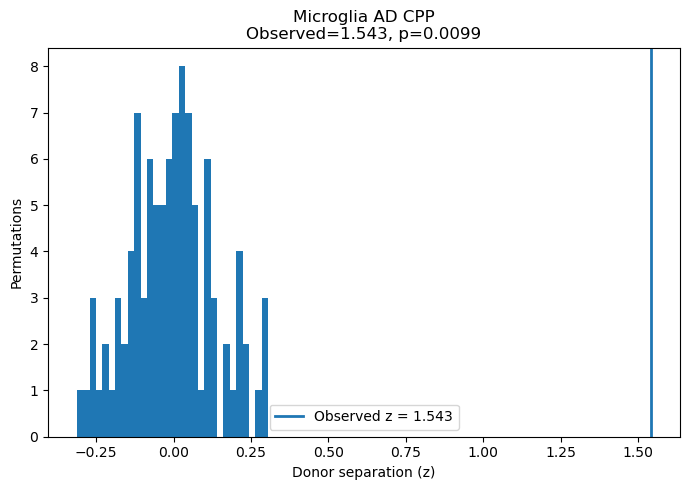

Observed z:   1.542508
Null mean:    -0.006836
Null SD:      0.137543
Permutation p: 0.009901


In [114]:
# ============================================================
# Permutation test
# ============================================================
import rpy2.robjects as ro
import time
import numpy as np
import matplotlib.pyplot as plt

N_PERM = 100

t0 = time.time()

real_z = donor_separation(scores)

null = []

for i in range(N_PERM):

    perm_scores = cpp_score(seed=100 + i)

    null.append(
        donor_separation(perm_scores)
    )

    if (i + 1) % 10 == 0:
        print(f"permutation {i+1}/{N_PERM}")

null = np.asarray(null, dtype=float)

print(f"\nDone in {time.time()-t0:.0f} s")

# Two-sided permutation p-value
p_perm = (
    np.sum(np.abs(null) >= np.abs(real_z)) + 1
) / (len(null) + 1)

plt.figure(figsize=(7, 5))

plt.hist(
    null,
    bins=30
)

plt.axvline(
    real_z,
    linewidth=2,
    label=f"Observed z = {real_z:.3f}"
)

plt.xlabel("Donor separation (z)")
plt.ylabel("Permutations")
plt.title(
    f"Microglia AD CPP\n"
    f"Observed={real_z:.3f}, p={p_perm:.4f}"
)

plt.legend()
plt.tight_layout()
plt.show()

print(f"Observed z:   {real_z:.6f}")
print(f"Null mean:    {null.mean():.6f}")
print(f"Null SD:      {null.std(ddof=1):.6f}")
print(f"Permutation p: {p_perm:.6f}")

In [38]:
# ============================================================
# SAVE MICROGLIA DIFFUSION CPP RESULTS
# ============================================================

import numpy as np
import scanpy as sc

# Align CPP scores to cells
adata.obs["AD_score"] = (
    scores["AD_score"]
    .reindex(adata.obs_names.astype(str))
    .values
)

# Store the 12-dimensional diffusion representation
adata.obsm["X_diffusion"] = np.asarray(diffusion_coords)

# Explicit name for downstream analyses
adata.obs["AD_score_diffusion_CPP"] = adata.obs["AD_score"].copy()

OUTFILE = "Microglia_AD_diffusion_CPP_scored.h5ad"

adata.write_h5ad(OUTFILE)

print("Saved:", OUTFILE)
print(adata)
print("\nCPP score:")
print(adata.obs["AD_score_diffusion_CPP"].describe())
print("\nX_diffusion shape:", adata.obsm["X_diffusion"].shape)
print("Missing CPP:", adata.obs["AD_score_diffusion_CPP"].isna().sum())

Saved: Microglia_AD_diffusion_CPP_scored.h5ad
AnnData object with n_obs × n_vars = 72994 × 1
    obs: 'cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP'
    obsm: 'X_pca', 'X_diffusion'

CPP score:
count    71205.000000
mean         0.061515
std          0.470606
min         -1.416351
25%         -0.261077
50%          0.057095
75%          0.396787
max          1.579821
Name: AD_score_diffusion_CPP, dtype: float64

X_diffusion shape: (72994, 12)
Missing CPP: 1789


In [3]:
%pip install "numpy==2.2.6" "numba>=0.61.2,<0.64"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 18.1 MB/s eta 0:00:00 MB/s eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.48.0 requires packaging<26,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.48.0 requires pillow<12,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install --force-reinstall --no-cache-dir "numpy==2.2.6"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 33.7 MB/s eta 0:00:0031m27.0 MB/s eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.48.0 requires packaging<26,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.48.0 requires pillow<12,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
print(np.__version__)

2.2.6


/opt/anaconda3/lib/python3.12/site-packages/matplotlib/colors.py:2293: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


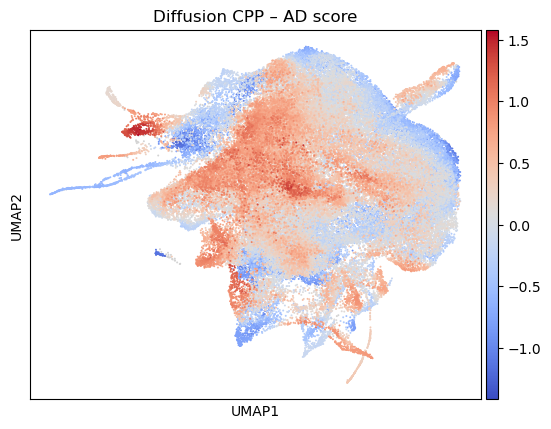

In [7]:
import scanpy as sc

ad_diff = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")

sc.pp.neighbors(
    ad_diff,
    use_rep="X_diffusion",
    n_neighbors=30,
    metric="euclidean",
    random_state=42
)

sc.tl.umap(
    ad_diff,
    random_state=42
)

sc.pl.umap(
    ad_diff,
    color="AD_score_diffusion_CPP",
    cmap="coolwarm",
    size=8,
    title="Diffusion CPP – AD score"
)

In [9]:
print("Same cell order:", original.obs_names.equals(adata.obs_names))

print("Same diffusion coordinates:",
      np.array_equal(
          original.obsm["X_diffusion"],
          adata.obsm["X_diffusion"],
          equal_nan=True
      ))

Same cell order: True
Same diffusion coordinates: True


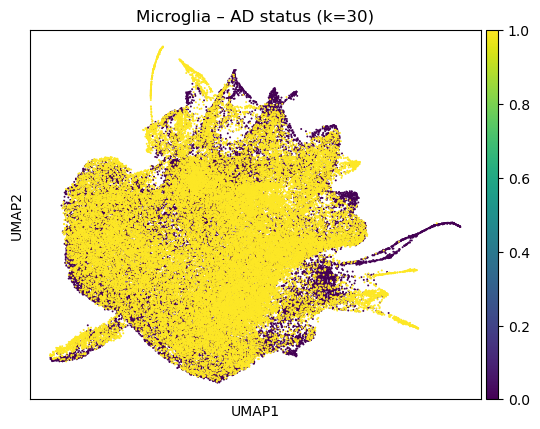

In [40]:
# ============================================================
# DISEASE STATUS ON DIFFUSION UMAP
# ============================================================

sc.pl.umap(
    ad_diff,
    color="AD_status",
    title="Microglia – AD status (k=30)",
    size=8
)

In [12]:
# ============================================================
# PREPARE 1D CPP SCORE SPACE FOR TOMATO
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from gudhi.clustering.tomato import Tomato

SCORE_COL = "AD_score_diffusion_CPP"
DONOR_COL = "subject"
DX_COL = "AD_status"       # 0 = control, 1 = AD

# Keep cells with finite CPP score
valid = np.isfinite(
    ad_diff.obs[SCORE_COL].to_numpy(dtype=float)
)

av = ad_diff[valid].copy()

# 1D CPP score space
Xs_raw = av.obs[[SCORE_COL]].to_numpy(dtype=float)

# Standardize
scaler = StandardScaler()
Xs = scaler.fit_transform(Xs_raw)

print("Cells:", av.n_obs)
print("ToMATo score-space shape:", Xs.shape)
print("Mean:", Xs.mean())
print("SD:", Xs.std())

Cells: 71205
ToMATo score-space shape: (71205, 1)
Mean: -1.9159357526288776e-17
SD: 1.0


In [13]:
# ============================================================
# TOMATO K SCAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gudhi.clustering.tomato import Tomato

K_VALUES = [10, 30, 50, 100, 150, 200, 250, 300, 350, 400]

rows = []

for k in K_VALUES:

    t = Tomato(
        graph_type="knn",
        metric="euclidean",
        density_type="logDTM",
        k=k,
        symmetrize_graph=True
    )

    t.fit(Xs)

    diagram = np.asarray(t.diagram_, dtype=float)

    birth = diagram[:, 0]
    death = diagram[:, 1]

    lifetime = birth - death

    finite = (
        np.isfinite(birth)
        & np.isfinite(death)
        & np.isfinite(lifetime)
        & (lifetime > 0)
    )

    life = lifetime[finite]

    if len(life) == 0:
        tau = np.nan
        n_clusters = 1
    else:
        tau = np.quantile(life, 0.90)
        n_clusters = max(1, int(np.sum(life > tau)))

    rows.append({
        "k": k,
        "finite_modes": len(life),
        "tau_90": tau,
        "n_clusters": n_clusters
    })

cluster_table = pd.DataFrame(rows)

display(cluster_table)

/opt/anaconda3/lib/python3.12/site-packages/gudhi/point_cloud/dtm.py:179: RuntimeWarning: divide by zero encountered in reciprocal
  density = dtm ** (-dim / q)
/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_15787/1430602562.py:32: RuntimeWarning: invalid value encountered in subtract
  lifetime = birth - death


,k,finite_modes,tau_90,n_clusters
0,10,4455,1.773898,446
1,30,1535,0.989938,154
2,50,939,0.750063,94
3,100,498,0.501859,50
4,150,299,0.398793,30
5,200,235,0.340957,24
6,250,183,0.309249,19
7,300,144,0.266496,15
8,350,125,0.238312,13
9,400,112,0.219771,12


In [34]:
# ============================================================
# FINAL TOMATO CLUSTERING
# k = 30
# ============================================================

K = 250

t = Tomato(
    graph_type="knn",
    metric="euclidean",
    density_type="logDTM",
    k=K,
    symmetrize_graph=True
)

t.fit(Xs)

diagram = np.asarray(t.diagram_, dtype=float)

birth = diagram[:, 0]
death = diagram[:, 1]

lifetime = birth - death

finite_life = lifetime[
    np.isfinite(lifetime) & (lifetime > 0)
]

tau = np.quantile(finite_life, 0.90)

t.merge_threshold_ = tau

labels = np.asarray(t.labels_)

av.obs["tomato_cpp"] = labels.astype(str)

print("k =", K)
print("tau90 =", tau)
print("n_clusters_ =", t.n_clusters_)
print("actual unique labels =", len(np.unique(labels)))

print("\nCluster sizes:")
print(
    av.obs["tomato_cpp"]
    .value_counts()
    .sort_index(key=lambda x: x.astype(int))
)

k = 250
tau90 = 0.30924932497941965
n_clusters_ = 20
actual unique labels = 20

Cluster sizes:
tomato_cpp
0      2553
1      1392
2      2734
3      2092
4      7698
5      1885
6      1784
7      3938
8      1669
9      2165
10     5928
11    13113
12     5641
13      626
14     1155
15     2245
16     4016
17     5332
18     2167
19     3072
Name: count, dtype: int64


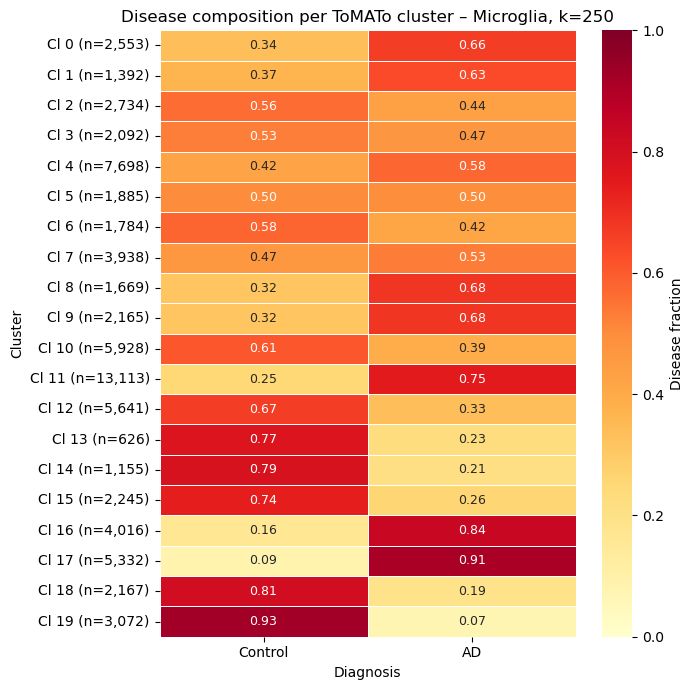

In [35]:
# ============================================================
# DISEASE COMPOSITION PER TOMATO CLUSTER
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CLUSTER_COL = "tomato_cpp"
DX_COL = "AD_status"

cl = av.obs[CLUSTER_COL].astype(str)
dx = av.obs[DX_COL].astype(int)

frac = pd.crosstab(
    cl,
    dx,
    normalize="index"
).reindex(columns=[0, 1], fill_value=0)

counts = cl.value_counts()

frac.columns = ["Control", "AD"]

order = sorted(frac.index, key=int)
frac = frac.loc[order]

frac.index = [
    f"Cl {i} (n={counts[i]:,})"
    for i in order
]

plt.figure(figsize=(7, max(6, 0.35 * len(frac))))

sns.heatmap(
    frac,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Disease fraction"},
    annot_kws={"fontsize": 9}
)

plt.xlabel("Diagnosis")
plt.ylabel("Cluster")
plt.title("Disease composition per ToMATo cluster – Microglia, k=250")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [36]:
CLUSTER_COL = "tomato_cpp"
DONOR_COL = "subject"

rows = []

for cl in sorted(av.obs[CLUSTER_COL].astype(str).unique(), key=int):

    obs = av.obs[av.obs[CLUSTER_COL].astype(str) == cl]
    d = obs[DONOR_COL].astype(str).value_counts()

    rows.append({
        "cluster": int(cl),
        "n_cells": len(obs),
        "n_donors": d.size,
        "top_donor": d.index[0],
        "top_donor_cells": int(d.iloc[0]),
        "top_donor_fraction": d.iloc[0] / len(obs)
    })

donor_table = pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)

display(
    donor_table.style.format({
        "top_donor_fraction": "{:.3f}"
    })
)

,cluster,n_cells,n_donors,top_donor,top_donor_cells,top_donor_fraction
0,0,2553,378,ROSMAP-23237,104,0.041
1,1,1392,341,ROSMAP-83589,28,0.020
2,2,2734,376,ROSMAP-20769,95,0.035
3,3,2092,359,ROSMAP-97522,44,0.021
4,4,7698,407,ROSMAP-97522,142,0.018
5,5,1885,354,ROSMAP-97522,38,0.020
6,6,1784,343,ROSMAP-20769,54,0.030
7,7,3938,403,ROSMAP-97522,77,0.020
8,8,1669,351,ROSMAP-23237,35,0.021
9,9,2165,356,ROSMAP-36875,55,0.025


In [37]:
import subprocess
import os

r_code = r'''
library(Seurat)
library(Matrix)

# Correct microglia object
obj <- readRDS("Microglia_preprocessed_PCA50.rds")

cat("Loaded Seurat object\n")
cat("Cells:", ncol(obj), "\n")
cat("Features:", nrow(obj), "\n")

# Extract RAW RNA counts
counts <- GetAssayData(
    obj,
    assay="RNA",
    layer="counts"
)

cat("RNA count matrix dimensions:\n")
cat("Genes:", nrow(counts), "\n")
cat("Cells:", ncol(counts), "\n")

# Save sparse matrix
Matrix::writeMM(
    counts,
    "microglia_counts.mtx"
)

# Save gene names
write.csv(
    data.frame(gene=rownames(counts)),
    "microglia_genes.csv",
    row.names=FALSE
)

# Save cell names
write.csv(
    data.frame(cell=colnames(counts)),
    "microglia_cells.csv",
    row.names=FALSE
)

# Save metadata
write.csv(
    obj@meta.data,
    "microglia_metadata.csv",
    row.names=TRUE
)

cat("DONE\n")
'''

env = os.environ.copy()
env["R_MAX_VSIZE"] = "48Gb"

result = subprocess.run(
    ["Rscript", "-e", r_code],
    capture_output=True,
    text=True,
    env=env
)

print("RETURN CODE:", result.returncode)

print("\nOUTPUT:")
print(result.stdout)

if result.returncode != 0:
    print("\nERROR:")
    print(result.stderr)

RETURN CODE: 0

OUTPUT:
Loaded Seurat object
Cells: 72994 
Features: 33538 
RNA count matrix dimensions:
Genes: 33538 
Cells: 72994 
NULL
DONE



In [38]:
import os
import glob

print("Current directory:")
print(os.getcwd())

print("\nRDS files available:")
for f in glob.glob("*.rds") + glob.glob("*.RDS"):
    print(f)

Current directory:
/Users/kellyshahu/Desktop/KellisLab/Spatial-Transcriptome-AD-project

RDS files available:
Astrocytes.rds
Astrocytes_metadata.rds
Astrocytes_preprocessed_PCA50.rds
Astrocytes_preprocessed_PCA50_UMAP.rds
Immune_cells.rds
Microglia_preprocessed_PCA50.rds
Vasculature_cells.rds


In [40]:
import scanpy as sc
import pandas as pd
import scipy.io
import scipy.sparse as sp
import anndata as ad

X = scipy.io.mmread(
    "microglia_counts.mtx"
).tocsr().T

genes = pd.read_csv(
    "microglia_genes.csv"
)["gene"].astype(str).values

cells = pd.read_csv(
    "microglia_cells.csv"
)["cell"].astype(str).values

meta = pd.read_csv(
    "microglia_metadata.csv",
    index_col=0
)

meta.index = meta.index.astype(str)
meta = meta.reindex(cells)

print("X:", X.shape)
print("genes:", len(genes))
print("cells:", len(cells))
print("metadata:", meta.shape)

adata_full = ad.AnnData(
    X=X,
    obs=meta,
    var=pd.DataFrame(index=genes)
)

adata_full.obs_names = cells
adata_full.var_names_make_unique()

adata_full.write_h5ad(
    "Microglia_full_counts.h5ad"
)

print(adata_full)
print("Saved Microglia_full_counts.h5ad")

X: (72994, 33538)
genes: 33538
cells: 72994
metadata: (72994, 7)
AnnData object with n_obs × n_vars = 72994 × 33538
    obs: 'cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD'
Saved Microglia_full_counts.h5ad


In [41]:
# ============================================================
# EXPORT CORRECT MICROGLIA TOMATO LABELS
# ============================================================

microglia_labels = pd.DataFrame({
    "cell": av.obs_names.astype(str),
    "tomato_cpp": av.obs["tomato_cpp"].astype(str).values
})

print("Number of labeled microglia cells:", len(microglia_labels))
print("\nCluster sizes:")
print(
    microglia_labels["tomato_cpp"]
    .astype(int)
    .value_counts()
    .sort_index()
)

microglia_labels.to_csv(
    "microglia_tomato_labels.csv",
    index=False
)

Number of labeled microglia cells: 71205

Cluster sizes:
tomato_cpp
0      2553
1      1392
2      2734
3      2092
4      7698
5      1885
6      1784
7      3938
8      1669
9      2165
10     5928
11    13113
12     5641
13      626
14     1155
15     2245
16     4016
17     5332
18     2167
19     3072
Name: count, dtype: int64


In [42]:
# ============================================================
# ATTACH MICROGLIA TOMATO LABELS TO FULL-COUNT OBJECT
# ============================================================

lab = pd.read_csv("microglia_tomato_labels.csv")

lab["cell"] = lab["cell"].astype(str)

lab = (
    lab
    .drop_duplicates("cell")
    .set_index("cell")
)

adata_full.obs["tomato_cpp"] = (
    lab["tomato_cpp"]
    .reindex(adata_full.obs_names.astype(str))
)

print(
    "Missing ToMATo labels:",
    adata_full.obs["tomato_cpp"].isna().sum()
)

print("\nCluster sizes:")
print(
    adata_full.obs["tomato_cpp"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

Missing ToMATo labels: 1789

Cluster sizes:
tomato_cpp
0      2553
1      1392
2      2734
3      2092
4      7698
5      1885
6      1784
7      3938
8      1669
9      2165
10     5928
11    13113
12     5641
13      626
14     1155
15     2245
16     4016
17     5332
18     2167
19     3072
Name: count, dtype: int64


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import scanpy as sc

CLUSTER_COL = "tomato_cpp"
DX_COL = "Pathologic_diagnosis_of_AD"
DONOR_COL = "subject"

micro = adata_full[adata_full.obs[CLUSTER_COL].notna()].copy()
micro.obs[CLUSTER_COL] = pd.to_numeric(micro.obs[CLUSTER_COL]).astype(int).astype(str)

print("Cells:", micro.n_obs)

print("\nClusters:")
print(
    micro.obs[CLUSTER_COL]
    .value_counts()
    .sort_index(key=lambda x: x.astype(int))
)

print("\nDiagnosis:")
print(micro.obs[DX_COL].value_counts(dropna=False))

print("\nDonors:", micro.obs[DONOR_COL].nunique())

Cells: 71205

Clusters:
tomato_cpp
0      2553
1      1392
2      2734
3      2092
4      7698
5      1885
6      1784
7      3938
8      1669
9      2165
10     5928
11    13113
12     5641
13      626
14     1155
15     2245
16     4016
17     5332
18     2167
19     3072
Name: count, dtype: int64

Diagnosis:
Pathologic_diagnosis_of_AD
yes    39453
no     31752
Name: count, dtype: int64

Donors: 424


Cells: 71205
Clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]

Diagnosis values:
Pathologic_diagnosis_of_AD
yes    39453
no     31752
Name: count, dtype: int64

Marker genes: 332

Disease counts:
Dx_clean    Control    AD
tomato_cpp               
0               857  1696
1               511   881
2              1540  1194
3              1110   982
4              3261  4437
5               948   937
6              1032   752
7              1842  2096
8               526  1143
9               685  1480
10             3592  2336
11             3316  9797
12             3753  1888
13              485   141
14              907   248
15             1664   581
16              648  3368
17              467  4865
18             1760   407
19             2848   224


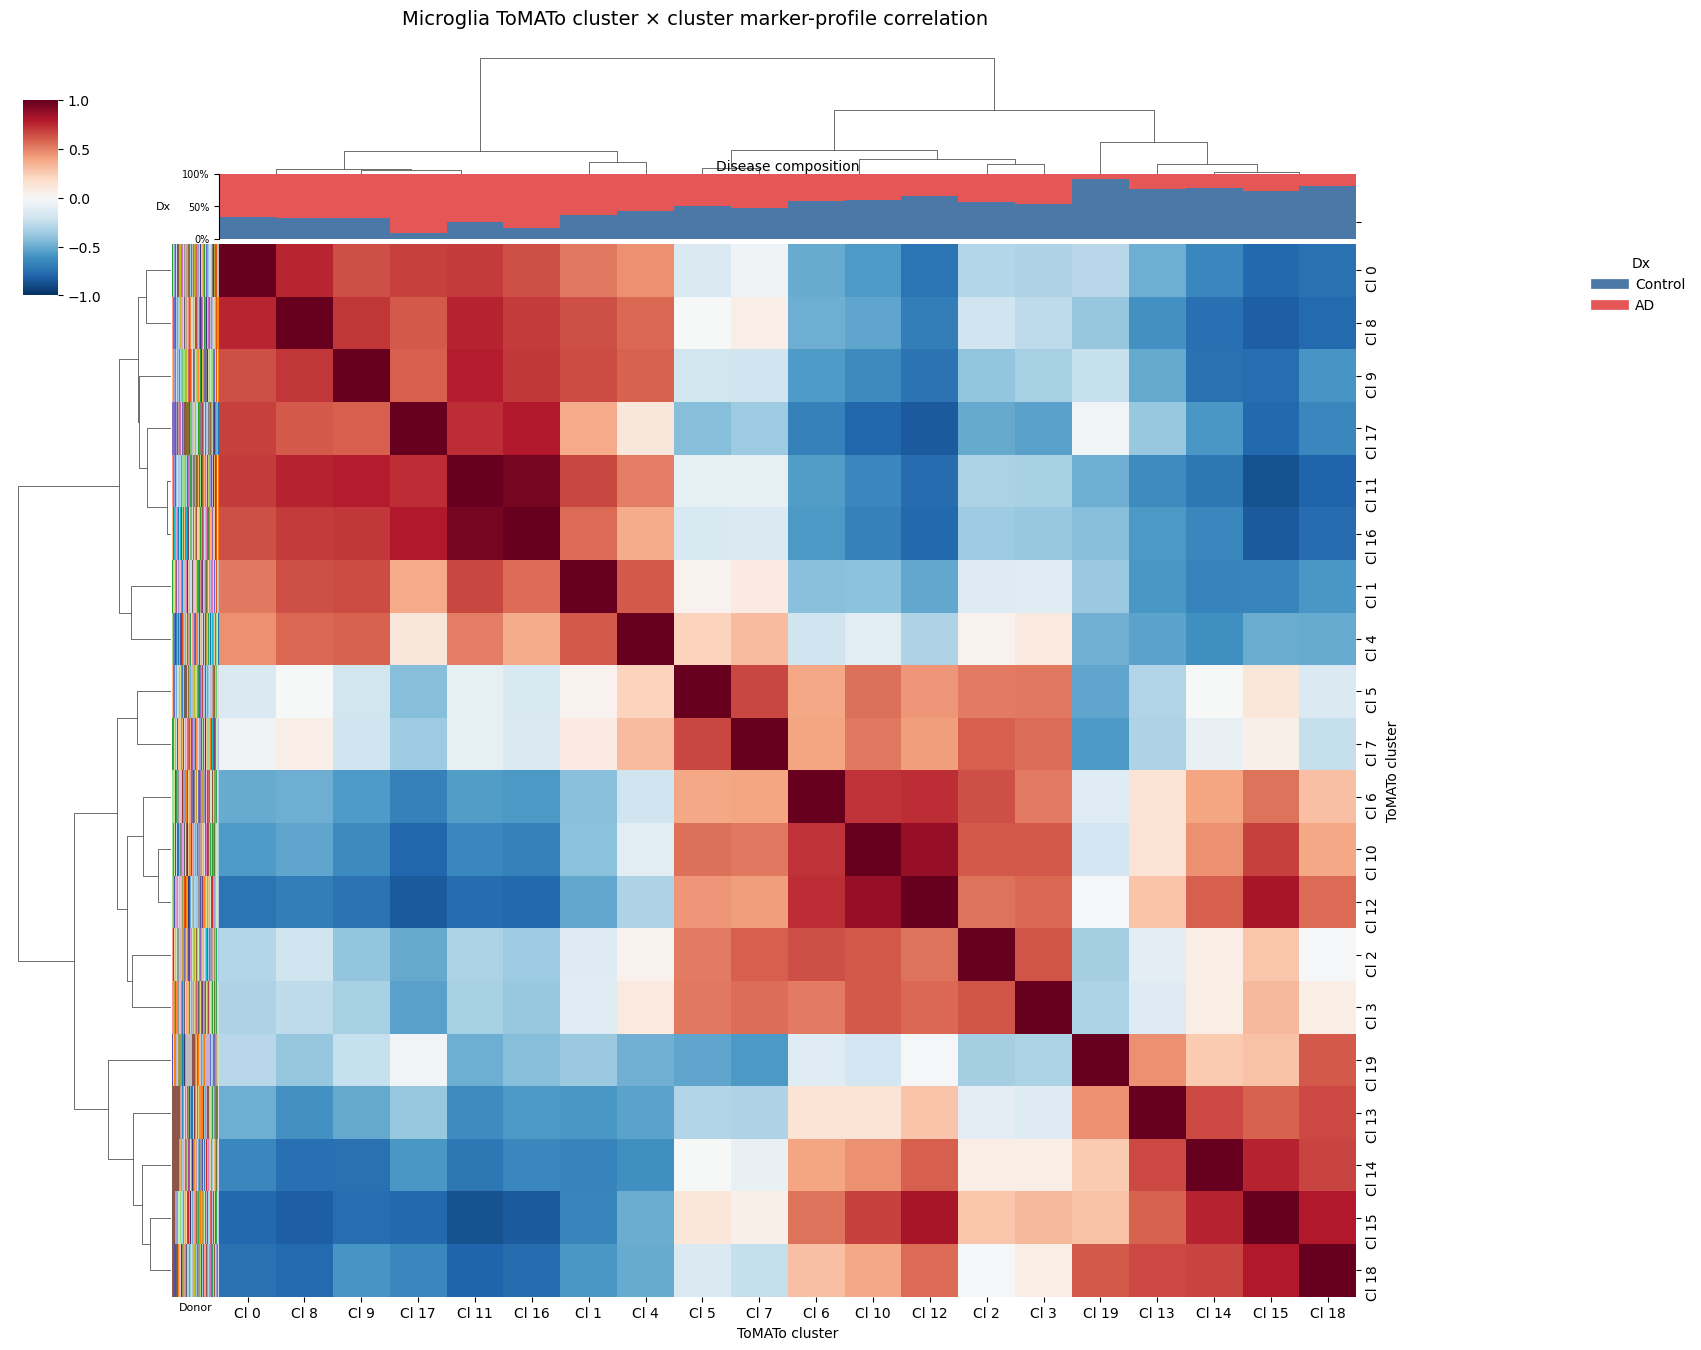


SUMMARY
Cells: 71205
Clusters: 20
Marker genes: 332
Control range: 0.08758439609902476 to 0.9270833333333334
AD range: 0.07291666666666667 to 0.9124156039009752


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import scanpy as sc
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

CLUSTER_COL = "tomato_cpp"
DX_COL = "Pathologic_diagnosis_of_AD"
DONOR_COL = "subject"

sc.pp.normalize_total(micro, target_sum=1e4)
sc.pp.log1p(micro)

clusters = sorted(micro.obs[CLUSTER_COL].dropna().astype(int).unique())
micro.obs[CLUSTER_COL] = pd.Categorical(
    micro.obs[CLUSTER_COL].astype("Int64").astype(str),
    categories=[str(c) for c in clusters]
)

print("Cells:", micro.n_obs)
print("Clusters:", clusters)
print("\nDiagnosis values:")
print(micro.obs[DX_COL].value_counts(dropna=False))

sc.tl.rank_genes_groups(micro, groupby=CLUSTER_COL, method="wilcoxon", key_added="tomato_markers")

genes = []

for cl in clusters:
    de = sc.get.rank_genes_groups_df(micro, group=str(cl), key="tomato_markers")
    de = de[(de["pvals_adj"] < 0.05) & (de["logfoldchanges"] > 0)]
    genes.extend(de.sort_values("pvals_adj").head(100)["names"].tolist())

genes = list(dict.fromkeys(g for g in genes if g in micro.var_names))
print("\nMarker genes:", len(genes))

X = micro[:, genes].X
X = X.toarray() if sp.issparse(X) else np.asarray(X)
labels = micro.obs[CLUSTER_COL].astype(str).to_numpy()

profiles = pd.DataFrame(
    [X[labels == str(cl)].mean(axis=0) for cl in clusters],
    index=[f"Cl {cl}" for cl in clusters],
    columns=genes
)

z = profiles.apply(lambda x: (x - x.mean()) / x.std(ddof=0), axis=0).fillna(0)
corr = z.T.corr()
corr.to_csv("microglia_tomato_cluster_correlation.csv")

dist = np.clip(1 - corr.values, 0, 2)
np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method="average")

dx = micro.obs[[CLUSTER_COL, DX_COL]].copy()
dx[CLUSTER_COL] = dx[CLUSTER_COL].astype(str)
dx["Dx_clean"] = dx[DX_COL].astype(str).str.lower().map({"no": "Control", "yes": "AD"})

disease_counts = pd.crosstab(dx[CLUSTER_COL], dx["Dx_clean"])
disease_counts = disease_counts.reindex(index=[str(c) for c in clusters], columns=["Control", "AD"], fill_value=0)
disease = disease_counts.div(disease_counts.sum(axis=1), axis=0).fillna(0)

print("\nDisease counts:")
print(disease_counts)

print("\nDisease composition:")
print(disease)

donor = pd.crosstab(
    micro.obs[CLUSTER_COL].astype(str),
    micro.obs[DONOR_COL].astype(str),
    normalize="index"
).reindex(index=[str(c) for c in clusters], fill_value=0)

donors = donor.columns.tolist()

palette = sns.color_palette("tab20", 20) + sns.color_palette("tab20b", 20) + sns.color_palette("tab20c", 20)
palette *= len(donors) // len(palette) + 1
donor_colors = dict(zip(donors, palette))

placeholder = pd.Series("white", index=corr.index)

g = sns.clustermap(
    corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    row_linkage=Z,
    col_linkage=Z,
    row_colors=placeholder,
    col_colors=placeholder,
    figsize=(14, 13),
    dendrogram_ratio=(0.12, 0.12),
    colors_ratio=(0.035, 0.035),
    cbar_pos=(0.02, 0.80, 0.025, 0.15)
)

co = [corr.columns[i].replace("Cl ", "") for i in g.dendrogram_col.reordered_ind]
ro = [corr.index[i].replace("Cl ", "") for i in g.dendrogram_row.reordered_ind]

print("\nHeatmap cluster order:")
print(co)

disease_ordered = disease.reindex(co).fillna(0)
heat_pos = g.ax_heatmap.get_position()

ax_dx = g.fig.add_axes([heat_pos.x0, heat_pos.y1 + 0.004, heat_pos.width, 0.050])

x = np.arange(len(co))
control_values = disease_ordered["Control"].to_numpy()
ad_values = disease_ordered["AD"].to_numpy()
colors = {"Control": "#4C78A8", "AD": "#E45756"}

ax_dx.bar(x, control_values, width=1.0, color=colors["Control"], edgecolor="none")
ax_dx.bar(x, ad_values, bottom=control_values, width=1.0, color=colors["AD"], edgecolor="none")

ax_dx.set_xlim(-0.5, len(co) - 0.5)
ax_dx.set_ylim(0, 1)
ax_dx.set_xticks([])
ax_dx.set_yticks([0, 0.5, 1])
ax_dx.set_yticklabels(["0%", "50%", "100%"], fontsize=7)
ax_dx.set_ylabel("Dx", rotation=0, ha="right", va="center", labelpad=8, fontsize=8)
ax_dx.set_title("Disease composition", fontsize=10, pad=2)

for spine in ["top", "right", "bottom"]:
    ax_dx.spines[spine].set_visible(False)

axr = g.ax_row_colors
axr.clear()

y = np.arange(len(ro)) + 0.5
left = np.zeros(len(ro))

for donor_id in donors:
    values = donor.reindex(ro)[donor_id].fillna(0).to_numpy()
    axr.barh(y, values, left=left, height=1, color=donor_colors[donor_id], linewidth=0)
    left += values

axr.set_xlim(0, 1)
axr.set_ylim(g.ax_heatmap.get_ylim())
axr.set_xticks([])
axr.set_yticks([])
axr.set_xlabel("Donor", fontsize=8)

g.ax_heatmap.set_xlabel("ToMATo cluster", fontsize=10)
g.ax_heatmap.set_ylabel("ToMATo cluster", fontsize=10)

handles = [
    plt.Line2D([0], [0], color=colors["Control"], linewidth=7),
    plt.Line2D([0], [0], color=colors["AD"], linewidth=7)
]

g.ax_heatmap.legend(
    handles,
    ["Control", "AD"],
    title="Dx",
    bbox_to_anchor=(1.20, 1),
    loc="upper left",
    frameon=False
)

g.fig.suptitle(
    "Microglia ToMATo cluster × cluster marker-profile correlation",
    y=1.02,
    fontsize=14
)

plt.show()

print("\nSUMMARY")
print("Cells:", micro.n_obs)
print("Clusters:", len(clusters))
print("Marker genes:", len(genes))
print("Control range:", disease["Control"].min(), "to", disease["Control"].max())
print("AD range:", disease["AD"].min(), "to", disease["AD"].max())

In [62]:
print("RAW VALUES:")
print(micro.obs["Pathologic_diagnosis_of_AD"].value_counts(dropna=False))

print("\nTYPE:")
print(micro.obs["Pathologic_diagnosis_of_AD"].dtype)

print("\nUNIQUE VALUES:")
print(micro.obs["Pathologic_diagnosis_of_AD"].unique())

RAW VALUES:
Pathologic_diagnosis_of_AD
yes    39453
no     31752
Name: count, dtype: int64

TYPE:
category

UNIQUE VALUES:
['no', 'yes']
Categories (2, object): ['no', 'yes']


In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import scipy.sparse as sp
import os

CLUSTER_COL = "tomato_cpp"
DX_COL = "Pathologic_diagnosis_of_AD"
DONOR_COL = "subject"

# ============================================================
# DEFINE MICROGLIA SUPER-NEIGHBORHOODS
# Replace with YOUR groups from the microglia heatmap
# ============================================================

SUPER_NEIGHBORHOODS = {
    # Upper-left correlated block
    "SN1": [
        0,8,9,17,11,16,1,4
    ],

    # Transitional / intermediate block
    "SN2": [
        5,7,6,10,12,2,3
    ],
    

    "SN3" :[
        19,13,14,15,18
    ]

   
    # add SN5, SN6, etc. if appropriate
}

SN_ORDER = list(SUPER_NEIGHBORHOODS.keys())

cluster_to_sn = {
    str(cluster): sn
    for sn, cluster_list in SUPER_NEIGHBORHOODS.items()
    for cluster in cluster_list
}

micro.obs["super_neighborhood"] = (
    pd.to_numeric(micro.obs[CLUSTER_COL], errors="coerce")
    .astype("Int64")
    .astype(str)
    .map(cluster_to_sn)
)

print(micro.obs["super_neighborhood"].value_counts(dropna=False))

super_neighborhood
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64


Super-neighborhood sizes:
super_neighborhood
SN1    37938
SN2    24002
SN3     9265
NaN     1789
Name: count, dtype: int64

Disease composition:


Diagnosis,Control,AD
super_neighborhood,,
SN1,0.270731,0.729269
SN2,0.575660,0.424340
SN3,0.827199,0.172801


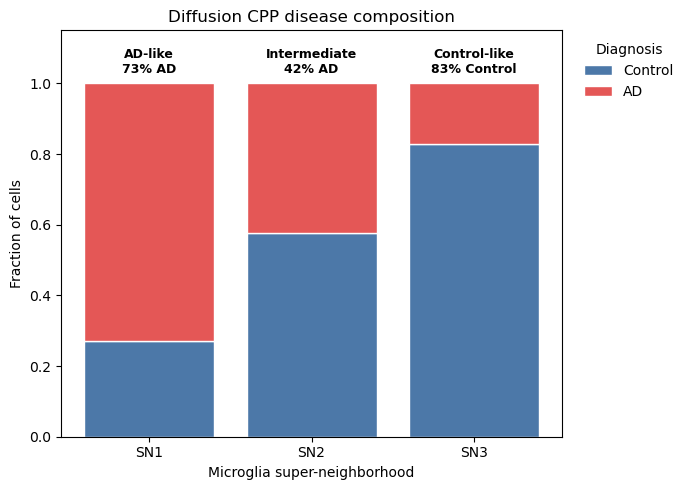

In [1]:

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

micro = sc.read_h5ad("Microglia_full_counts.h5ad")

lab = pd.read_csv("microglia_tomato_labels.csv")
lab["cell"] = lab["cell"].astype(str)
lab = lab.drop_duplicates("cell").set_index("cell")

micro.obs["tomato_cpp"] = lab["tomato_cpp"].reindex(
    micro.obs_names.astype(str)
).to_numpy()

SUPER_NEIGHBORHOODS = {
    "SN1": [0, 8, 9, 17, 11, 16, 1, 4],
    "SN2": [5, 7, 6, 10, 12, 2, 3],
    "SN3": [19, 13, 14, 15, 18]
}

SN_ORDER = ["SN1", "SN2", "SN3"]
DX_COL = "Pathologic_diagnosis_of_AD"

cluster_to_sn = {
    str(cluster): sn
    for sn, clusters in SUPER_NEIGHBORHOODS.items()
    for cluster in clusters
}

micro.obs["super_neighborhood"] = (
    pd.to_numeric(micro.obs["tomato_cpp"], errors="coerce")
    .astype("Int64")
    .astype(str)
    .map(cluster_to_sn)
)

print("Super-neighborhood sizes:")
print(micro.obs["super_neighborhood"].value_counts(dropna=False))

df = micro.obs[["super_neighborhood", DX_COL]].dropna().copy()

df["Diagnosis"] = (
    df[DX_COL]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"no": "Control", "yes": "AD"})
)

df = df.dropna(subset=["Diagnosis"])

composition = (
    pd.crosstab(
        df["super_neighborhood"],
        df["Diagnosis"],
        normalize="index"
    )
    .reindex(SN_ORDER)
    .reindex(columns=["Control", "AD"], fill_value=0)
)

print("\nDisease composition:")
display(composition)

colors = {"Control": "#4C78A8", "AD": "#E45756"}

state_labels = {
    "SN1": "AD-like",
    "SN2": "Intermediate",
    "SN3": "Control-like"
}

fig, ax = plt.subplots(figsize=(7, 5))
bottom = np.zeros(len(SN_ORDER))

for diagnosis in ["Control", "AD"]:
    values = composition[diagnosis].values

    ax.bar(
        SN_ORDER,
        values,
        bottom=bottom,
        label=diagnosis,
        color=colors[diagnosis],
        edgecolor="white"
    )
    bottom += values

for i, sn in enumerate(SN_ORDER):
    ad_frac = composition.loc[sn, "AD"]
    ctrl_frac = composition.loc[sn, "Control"]

    if sn == "SN1":
        percentage_label = f"{ad_frac:.0%} AD"
    elif sn == "SN2":
        percentage_label = f"{ad_frac:.0%} AD"
    else:
        percentage_label = f"{ctrl_frac:.0%} Control"

    ax.text(
        i, 1.02,
        f"{state_labels[sn]}\n{percentage_label}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_ylim(0, 1.15)
ax.set_xlabel("Microglia super-neighborhood")
ax.set_ylabel("Fraction of cells")
ax.set_title("Diffusion CPP disease composition")
ax.legend(
    title="Diagnosis",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.savefig("Diffusion_CPP_microglia_SN_composition.png", dpi=300, bbox_inches="tight")
plt.show()

micro.obs[["tomato_cpp", "super_neighborhood"]].to_csv(
    "diffusionCPP_microglia_super_neighborhood_labels.csv",
    index_label="cell"
)


In [55]:
# ============================================================
# SAVE MICROGLIA SUPER-NEIGHBORHOOD LABELS
# ============================================================

sn_labels = pd.DataFrame({
    "cell": micro.obs_names.astype(str),
    "SN": micro.obs["super_neighborhood"]
})

sn_labels = sn_labels.dropna()

sn_labels.to_csv(
    "microglia_SN_labels.csv",
    index=False
)

print(sn_labels["SN"].value_counts())
print("Total labeled cells:", len(sn_labels))
print("Saved: microglia_SN_labels.csv")

SN
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64
Total labeled cells: 71205
Saved: microglia_SN_labels.csv


In [66]:
# ============================================================
# LOAD FULL-COUNT MICROGLIA DATA
# ============================================================

import anndata as ad

adata_sn = ad.read_h5ad("Microglia_full_counts.h5ad")

sn_labels = pd.read_csv("microglia_SN_labels.csv")
sn_labels["cell"] = sn_labels["cell"].astype(str)

sn_map = sn_labels.set_index("cell")["SN"]

adata_sn.obs["super_neighborhood"] = (
    pd.Series(
        adata_sn.obs_names.astype(str),
        index=adata_sn.obs_names
    )
    .map(sn_map)
)

adata_sn = adata_sn[
    adata_sn.obs["super_neighborhood"].notna()
].copy()

adata_sn.obs["super_neighborhood"] = (
    adata_sn.obs["super_neighborhood"].astype("category")
)

print("Shape:", adata_sn.shape)
print("\nSuper-neighborhoods:")
print(adata_sn.obs["super_neighborhood"].value_counts())

Shape: (71205, 33538)

Super-neighborhoods:
super_neighborhood
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64


In [57]:
# ============================================================
# NORMALIZE + LOG1P FOR DIFFERENTIAL EXPRESSION
# ============================================================

sc.pp.normalize_total(
    adata_sn,
    target_sum=1e4
)

sc.pp.log1p(adata_sn)

print("Normalization complete.")

Normalization complete.


In [58]:
# ============================================================
# SUPER-NEIGHBORHOOD DIFFERENTIAL EXPRESSION
# ============================================================

FDR_THRESHOLD = 0.05
MIN_ABS_LOGFC = 0.25

groups = [
    str(x)
    for x in adata_sn.obs["super_neighborhood"].cat.categories
    if (adata_sn.obs["super_neighborhood"] == x).sum() > 0
]

sc.tl.rank_genes_groups(
    adata_sn,
    groupby="super_neighborhood",
    groups=groups,
    reference="rest",
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    use_raw=False,
    pts=True,
    key_added="microglia_SN_DE"
)

de_results = {}
summary_rows = []

os.makedirs("microglia_SN_DE", exist_ok=True)

for sn in groups:

    result = (
        sc.get.rank_genes_groups_df(
            adata_sn,
            group=sn,
            key="microglia_SN_DE"
        )
        .rename(columns={
            "names": "gene",
            "scores": "wilcoxon_score",
            "logfoldchanges": "log2_fold_change",
            "pvals": "p_value",
            "pvals_adj": "adjusted_p_value"
        })
    )

    result["super_neighborhood"] = sn

    result["significant"] = (
        result["adjusted_p_value"].notna()
        & (result["adjusted_p_value"] < FDR_THRESHOLD)
        & (result["log2_fold_change"].abs() >= MIN_ABS_LOGFC)
    )

    result["direction"] = "Not significant"

    result.loc[
        result["significant"] &
        (result["log2_fold_change"] > 0),
        "direction"
    ] = "Upregulated"

    result.loc[
        result["significant"] &
        (result["log2_fold_change"] < 0),
        "direction"
    ] = "Downregulated"

    sig = result[result["significant"]]

    up = sig[sig["log2_fold_change"] > 0].sort_values(
        "adjusted_p_value"
    )

    down = sig[sig["log2_fold_change"] < 0].sort_values(
        "adjusted_p_value"
    )

    result.to_csv(
        f"microglia_SN_DE/{sn}_all_DE.csv",
        index=False
    )

    up.to_csv(
        f"microglia_SN_DE/{sn}_upregulated.csv",
        index=False
    )

    down.to_csv(
        f"microglia_SN_DE/{sn}_downregulated.csv",
        index=False
    )

    de_results[sn] = result

    summary_rows.append({
        "super_neighborhood": sn,
        "n_cells": int(
            (adata_sn.obs["super_neighborhood"] == sn).sum()
        ),
        "upregulated_genes": up["gene"].nunique(),
        "downregulated_genes": down["gene"].nunique(),
        "total_significant_genes": sig["gene"].nunique()
    })

de_summary = pd.DataFrame(summary_rows)

display(de_summary)

,super_neighborhood,n_cells,upregulated_genes,downregulated_genes,total_significant_genes
0,SN1,37938,2070,77,2147
1,SN2,24002,26,2814,2840
2,SN3,9265,211,145,356


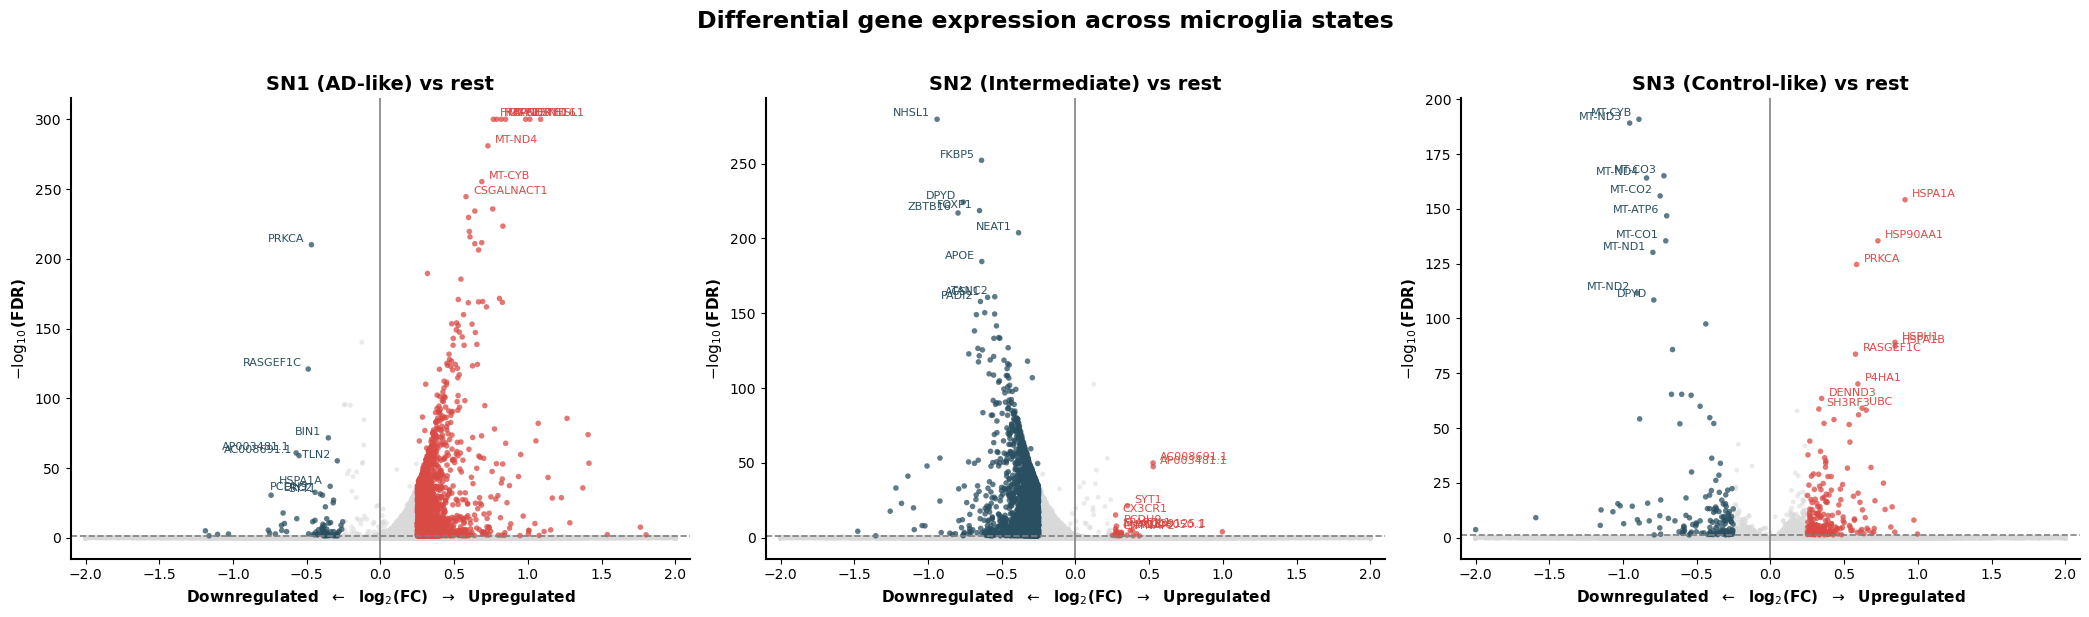

In [59]:
import numpy as np
import matplotlib.pyplot as plt

labels = {"SN1": "AD-like", "SN2": "Intermediate", "SN3": "Control-like"}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

XMAX = 2.0
N_LABELS = 10

for ax, sn in zip(axes, ["SN1", "SN2", "SN3"]):

    r = de_results[sn].dropna(
        subset=["gene", "log2_fold_change", "adjusted_p_value"]
    ).copy()

    r["neglogFDR"] = -np.log10(r["adjusted_p_value"].clip(lower=1e-300))

    # Clip ONLY for plotting so extreme FC values do not destroy the volcano shape
    r["plot_logFC"] = r["log2_fold_change"].clip(-XMAX, XMAX)

    up = r["direction"].eq("Upregulated")
    down = r["direction"].eq("Downregulated")
    ns = ~(up | down)

    ax.scatter(
        r.loc[ns, "plot_logFC"],
        r.loc[ns, "neglogFDR"],
        s=12,
        c="#D9D9D9",
        alpha=0.55,
        edgecolors="none"
    )

    ax.scatter(
        r.loc[down, "plot_logFC"],
        r.loc[down, "neglogFDR"],
        s=16,
        c="#294F60",
        alpha=0.75,
        edgecolors="none"
    )

    ax.scatter(
        r.loc[up, "plot_logFC"],
        r.loc[up, "neglogFDR"],
        s=16,
        c="#D94A45",
        alpha=0.75,
        edgecolors="none"
    )

    ax.axvline(0, color="gray", linewidth=1.2)
    ax.axhline(
        -np.log10(FDR_THRESHOLD),
        color="gray",
        linestyle="--",
        linewidth=1.2
    )

    top_up = r.loc[up].sort_values("adjusted_p_value").head(N_LABELS)
    top_down = r.loc[down].sort_values("adjusted_p_value").head(N_LABELS)

    for _, row in top_up.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#D94A45",
            ha="left"
        )

    for _, row in top_down.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(-5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#294F60",
            ha="right"
        )

    ax.set_xlim(-2.1, 2.1)

    ax.set_title(
        f"{sn} ({labels[sn]}) vs rest",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        r"Downregulated  $\leftarrow$  log$_2$(FC)  $\rightarrow$  Upregulated",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"$-\log_{10}$(FDR)",
        fontsize=11,
        fontweight="bold"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    ax.tick_params(labelsize=10)

plt.suptitle(
    "Differential gene expression across microglia states",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

microglia_SN_DE/SN1_upregulated.csv FOUND
microglia_SN_DE/SN1_downregulated.csv FOUND
microglia_SN_DE/SN2_upregulated.csv FOUND
microglia_SN_DE/SN2_downregulated.csv FOUND
microglia_SN_DE/SN3_upregulated.csv FOUND
microglia_SN_DE/SN3_downregulated.csv FOUND

R OUTPUT:
SN1 Up : 2070 genes
Saved: microglia_SN_pathway_enrichment/SN1_Up_GO_BP.csv | 460 pathways
SN1 Down : 77 genes
Saved: microglia_SN_pathway_enrichment/SN1_Down_GO_BP.csv | 231 pathways
SN2 Up : 26 genes
Saved: microglia_SN_pathway_enrichment/SN2_Up_GO_BP.csv | 101 pathways
SN2 Down : 2814 genes
Saved: microglia_SN_pathway_enrichment/SN2_Down_GO_BP.csv | 628 pathways
SN3 Up : 211 genes
Saved: microglia_SN_pathway_enrichment/SN3_Up_GO_BP.csv | 168 pathways
SN3 Down : 145 genes
Saved: microglia_SN_pathway_enrichment/SN3_Down_GO_BP.csv | 240 pathways


R STDERR:
Warning message:
package ‘S4Vectors’ was built under R version 4.6.1 
'select()' returned 1:many mapping between keys and columns
'select()' returned 1:1 mapping betwe

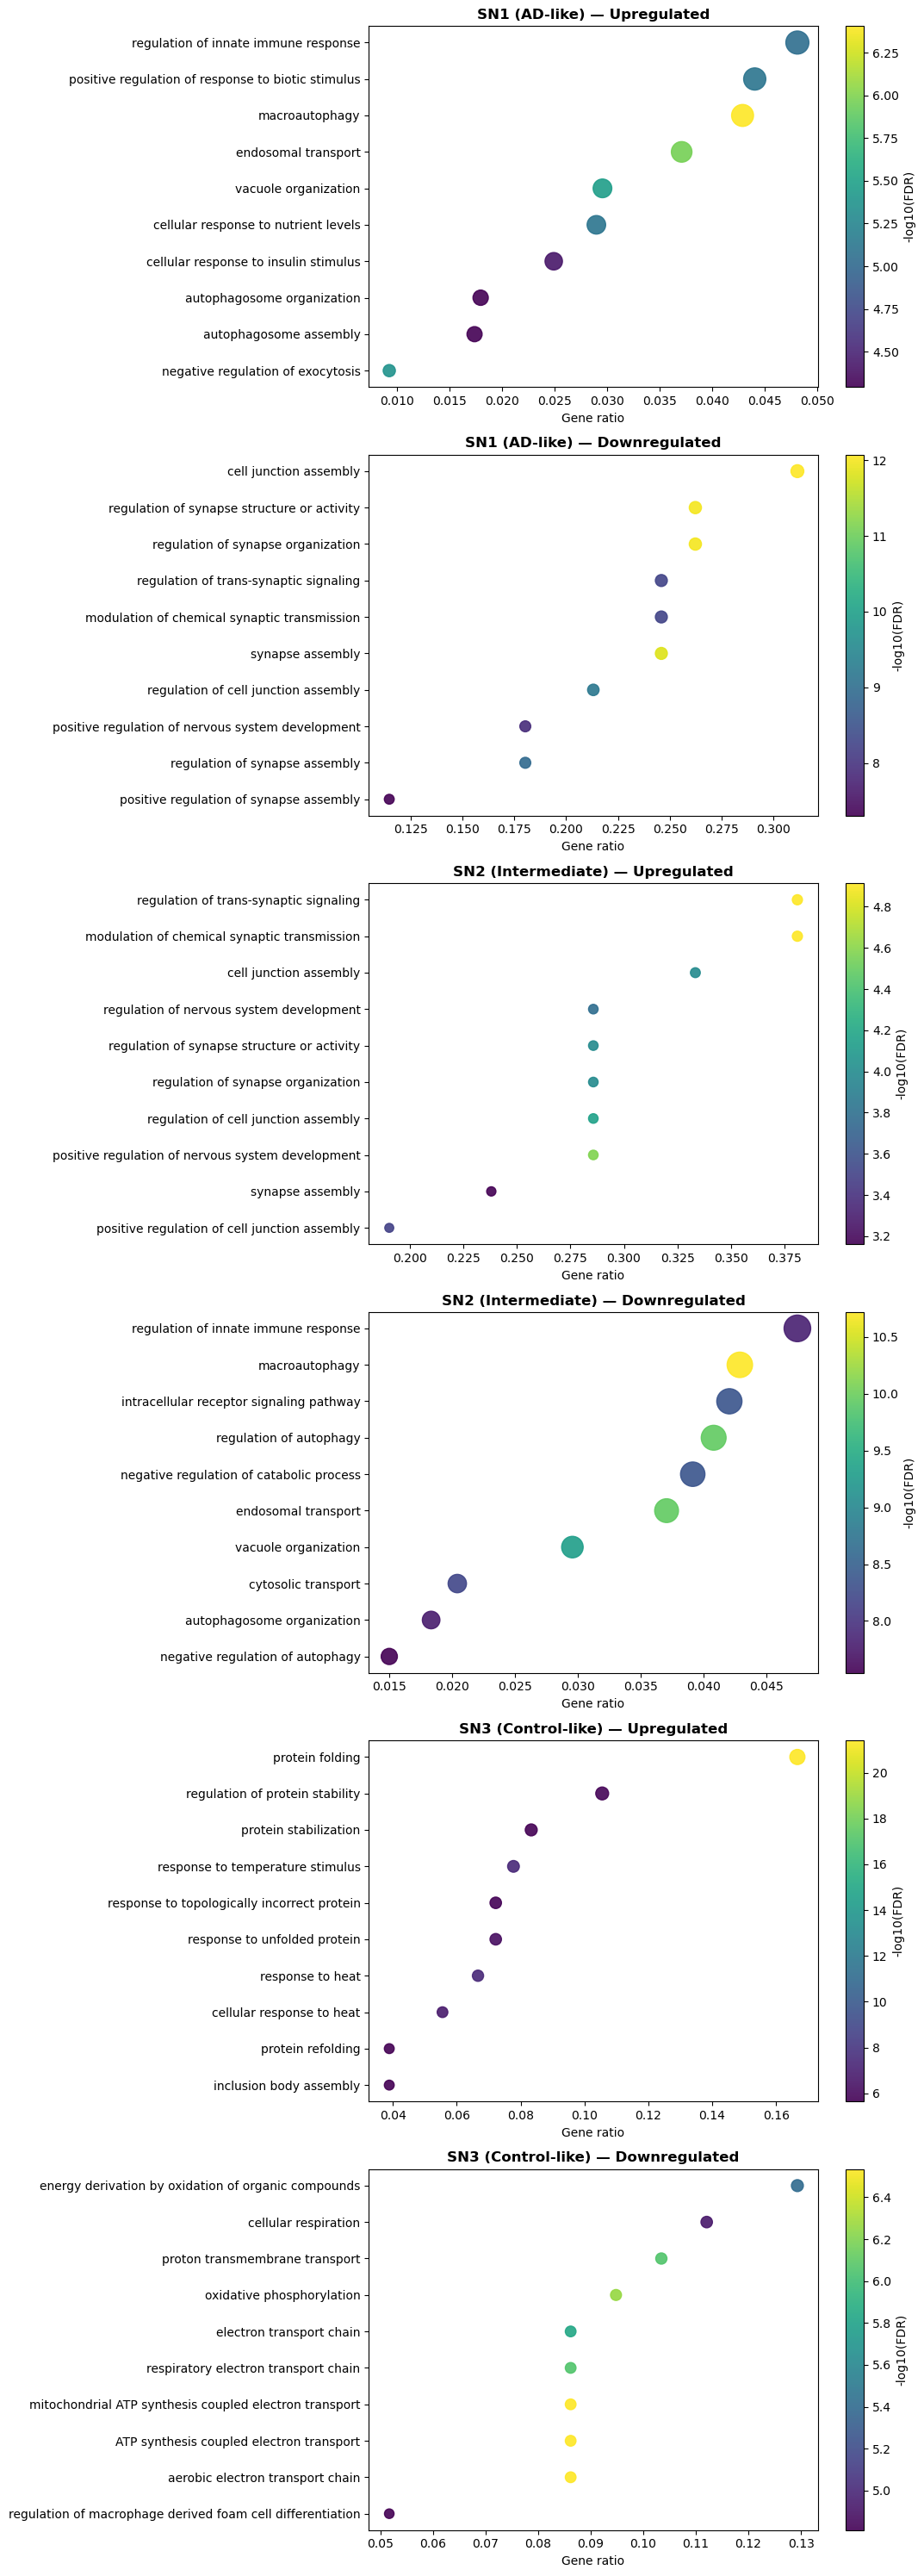

In [60]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DE_DIR = "microglia_SN_DE"
ENRICH_DIR = "microglia_SN_pathway_enrichment"
os.makedirs(ENRICH_DIR, exist_ok=True)

SN_LABELS = {"SN1": "AD-like", "SN2": "Intermediate", "SN3": "Control-like"}

for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["upregulated", "downregulated"]:
        f = f"{DE_DIR}/{sn}_{direction}.csv"
        print(f, "FOUND" if os.path.exists(f) else "MISSING")

r_code = f'''
suppressPackageStartupMessages({{
    library(clusterProfiler)
    library(org.Hs.eg.db)
}})

DE_DIR <- "{DE_DIR}"
OUTDIR <- "{ENRICH_DIR}"

for (sn in c("SN1", "SN2", "SN3")) {{
    for (direction in c("Up", "Down")) {{

        suffix <- ifelse(direction == "Up", "upregulated", "downregulated")
        file <- file.path(DE_DIR, paste0(sn, "_", suffix, ".csv"))

        if (!file.exists(file)) {{
            cat("Missing:", file, "\\n")
            next
        }}

        dat <- read.csv(file, stringsAsFactors=FALSE)
        genes <- unique(na.omit(as.character(dat$gene)))
        genes <- genes[genes != ""]

        cat(sn, direction, ":", length(genes), "genes\\n")

        if (length(genes) < 3) {{
            cat("Too few genes — skipping\\n")
            next
        }}

        ego <- enrichGO(
            gene=genes, OrgDb=org.Hs.eg.db, keyType="SYMBOL", ont="BP",
            pAdjustMethod="BH", pvalueCutoff=0.05, qvalueCutoff=0.20,
            readable=TRUE
        )

        res <- as.data.frame(ego)

        if (nrow(res) == 0) {{
            cat("No enrichment\\n")
            next
        }}

        res <- res[!is.na(res$p.adjust) & res$p.adjust < 0.05, ]

        if (nrow(res) == 0) {{
            cat("No FDR-significant pathways\\n")
            next
        }}

        ratio <- strsplit(as.character(res$GeneRatio), "/")
        res$GeneRatioNum <- sapply(ratio, function(x) as.numeric(x[1]) / as.numeric(x[2]))
        res$SN <- sn
        res$Direction <- direction

        outfile <- file.path(OUTDIR, paste0(sn, "_", direction, "_GO_BP.csv"))
        write.csv(res, outfile, row.names=FALSE)

        cat("Saved:", outfile, "|", nrow(res), "pathways\\n")
    }}
}}
'''

result = subprocess.run(["Rscript", "-e", r_code], capture_output=True, text=True)

print("\nR OUTPUT:")
print(result.stdout)

if result.stderr:
    print("\nR STDERR:")
    print(result.stderr)

plot_data = []

for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["Up", "Down"]:
        f = f"{ENRICH_DIR}/{sn}_{direction}_GO_BP.csv"
        if os.path.exists(f):
            plot_data.append((sn, direction, pd.read_csv(f)))

print("\nEnrichment plots available:", len(plot_data))

if plot_data:

    fig, axes = plt.subplots(len(plot_data), 1, figsize=(11, 5 * len(plot_data)))
    axes = np.atleast_1d(axes)

    for ax, (sn, direction, df) in zip(axes, plot_data):

        top = df.sort_values("p.adjust").head(10).sort_values("GeneRatioNum").copy()
        top["neglogFDR"] = -np.log10(top["p.adjust"].clip(lower=1e-300))
        y = np.arange(len(top))

        scatter = ax.scatter(
            top["GeneRatioNum"], y,
            s=40 + top["Count"] * 4,
            c=top["neglogFDR"],
            cmap="viridis",
            alpha=0.9
        )

        ax.set_yticks(y)
        ax.set_yticklabels(top["Description"])
        ax.set_xlabel("Gene ratio")
        ax.set_title(f"{sn} ({SN_LABELS[sn]}) — {direction}regulated", fontweight="bold")

        plt.colorbar(scatter, ax=ax, label="-log10(FDR)")

    plt.tight_layout()
    plt.show()

else:
    print("No enrichment files were generated.")

In [65]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


# Within AD heterogeneity
(here I ask: the previous analysis doing differential expression analysis between superneighborhoods but then I thought, do the geens represent differences in AD heterogeneity or they come from the control cells? So, this motidated a secondry analysis doing differential expressson analysis only within AD cells in teh three superneighborhoods).

In [4]:
print(adata.obs["Pathologic_diagnosis_of_AD"].value_counts(dropna=False))

Pathologic_diagnosis_of_AD
yes    39453
no     31752
Name: count, dtype: int64


In [8]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np

# Load data + saved super-neighborhood labels
# Keep AD cells only
adata_ad = adata[adata.obs["Pathologic_diagnosis_of_AD"] == "yes"].copy()
adata_ad.obs["SN"] = adata_ad.obs["SN"].astype("category")

print("AD cells:", adata_ad.n_obs)
print(adata_ad.obs["SN"].value_counts())

# Normalize exactly as before
sc.pp.normalize_total(adata_ad, target_sum=1e4)
sc.pp.log1p(adata_ad)

FDR_THRESHOLD = 0.05
MIN_ABS_LOGFC = 0.25

groups = [str(x) for x in adata_ad.obs["SN"].cat.categories if (adata_ad.obs["SN"] == x).sum() > 0]

sc.tl.rank_genes_groups(
    adata_ad,
    groupby="SN",
    groups=groups,
    reference="rest",
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    use_raw=False,
    pts=True,
    key_added="AD_SN_DE"
)

de_results = {}
summary_rows = []

for sn in groups:

    result = sc.get.rank_genes_groups_df(
        adata_ad,
        group=sn,
        key="AD_SN_DE"
    ).rename(columns={
        "names": "gene",
        "scores": "wilcoxon_score",
        "logfoldchanges": "log2_fold_change",
        "pvals": "p_value",
        "pvals_adj": "adjusted_p_value"
    })

    result["SN"] = sn

    result["significant"] = (
        (result["adjusted_p_value"] < FDR_THRESHOLD) &
        (result["log2_fold_change"].abs() >= MIN_ABS_LOGFC)
    )

    sig = result[result["significant"]]
    up = sig[sig["log2_fold_change"] > 0]
    down = sig[sig["log2_fold_change"] < 0]

    de_results[sn] = result

    summary_rows.append({
        "SN": sn,
        "AD_cells": (adata_ad.obs["SN"] == sn).sum(),
        "upregulated": up["gene"].nunique(),
        "downregulated": down["gene"].nunique(),
        "total_DEGs": sig["gene"].nunique()
    })

de_summary = pd.DataFrame(summary_rows)
display(de_summary)

AD cells: 39453
SN
SN1    27667
SN2    10185
SN3     1601
Name: count, dtype: int64


,SN,AD_cells,upregulated,downregulated,total_DEGs
0,SN1,27667,4567,24,4591
1,SN2,10185,19,4144,4163
2,SN3,1601,17,949,966


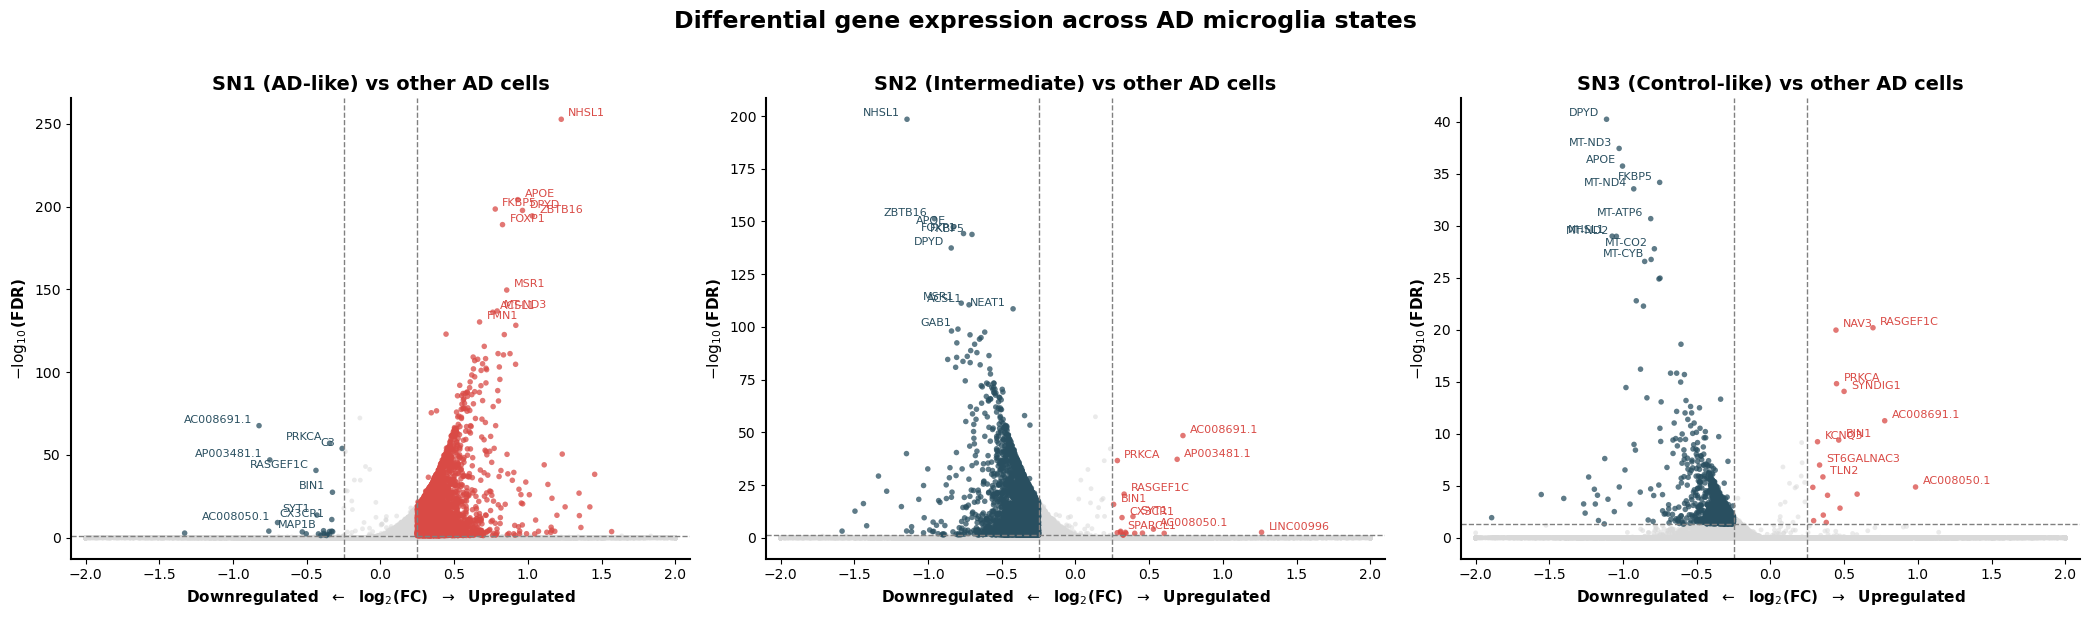

In [9]:
import numpy as np
import matplotlib.pyplot as plt

labels = {
    "SN1": "AD-like",
    "SN2": "Intermediate",
    "SN3": "Control-like"
}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

XMAX = 2.0
N_LABELS = 10

for ax, sn in zip(axes, ["SN1", "SN2", "SN3"]):

    r = de_results[sn].dropna(
        subset=["gene", "log2_fold_change", "adjusted_p_value"]
    ).copy()

    r["neglogFDR"] = -np.log10(
        r["adjusted_p_value"].clip(lower=1e-300)
    )

    # Clip only for visualization
    r["plot_logFC"] = r["log2_fold_change"].clip(-XMAX, XMAX)

    up = (
        (r["adjusted_p_value"] < FDR_THRESHOLD) &
        (r["log2_fold_change"] >= MIN_ABS_LOGFC)
    )

    down = (
        (r["adjusted_p_value"] < FDR_THRESHOLD) &
        (r["log2_fold_change"] <= -MIN_ABS_LOGFC)
    )

    ns = ~(up | down)

    # Non-significant
    ax.scatter(
        r.loc[ns, "plot_logFC"],
        r.loc[ns, "neglogFDR"],
        s=12,
        c="#D9D9D9",
        alpha=0.55,
        edgecolors="none"
    )

    # Downregulated
    ax.scatter(
        r.loc[down, "plot_logFC"],
        r.loc[down, "neglogFDR"],
        s=16,
        c="#294F60",
        alpha=0.75,
        edgecolors="none"
    )

    # Upregulated
    ax.scatter(
        r.loc[up, "plot_logFC"],
        r.loc[up, "neglogFDR"],
        s=16,
        c="#D94A45",
        alpha=0.75,
        edgecolors="none"
    )

    # Threshold lines
    ax.axvline(
        -MIN_ABS_LOGFC,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.axvline(
        MIN_ABS_LOGFC,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.axhline(
        -np.log10(FDR_THRESHOLD),
        color="gray",
        linestyle="--",
        linewidth=1
    )

    # Label top significant genes
    top_up = (
        r.loc[up]
        .sort_values("adjusted_p_value")
        .head(N_LABELS)
    )

    top_down = (
        r.loc[down]
        .sort_values("adjusted_p_value")
        .head(N_LABELS)
    )

    for _, row in top_up.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#D94A45",
            ha="left"
        )

    for _, row in top_down.iterrows():
        ax.annotate(
            row["gene"],
            (row["plot_logFC"], row["neglogFDR"]),
            xytext=(-5, 2),
            textcoords="offset points",
            fontsize=8,
            color="#294F60",
            ha="right"
        )

    ax.set_xlim(-2.1, 2.1)

    ax.set_title(
        f"{sn} ({labels[sn]}) vs other AD cells",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        r"Downregulated  $\leftarrow$  log$_2$(FC)  $\rightarrow$  Upregulated",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"$-\log_{10}$(FDR)",
        fontsize=11,
        fontweight="bold"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    ax.tick_params(labelsize=10)

plt.suptitle(
    "Differential gene expression across AD microglia states",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [11]:
import os

os.makedirs("AD_SN_DE", exist_ok=True)

for sn in ["SN1", "SN2", "SN3"]:

    result = de_results[sn]

    sig = result[
        (result["adjusted_p_value"] < 0.05) &
        (result["log2_fold_change"].abs() >= 0.25)
    ].copy()

    up = sig[sig["log2_fold_change"] > 0].copy()
    down = sig[sig["log2_fold_change"] < 0].copy()

    up.to_csv(f"AD_SN_DE/{sn}_upregulated.csv", index=False)
    down.to_csv(f"AD_SN_DE/{sn}_downregulated.csv", index=False)

    print(
        f"{sn}: "
        f"{len(up)} up | "
        f"{len(down)} down"
    )

SN1: 4567 up | 24 down
SN2: 19 up | 4144 down
SN3: 17 up | 949 down


AD_SN_DE/SN1_upregulated.csv FOUND
AD_SN_DE/SN1_downregulated.csv FOUND
AD_SN_DE/SN2_upregulated.csv FOUND
AD_SN_DE/SN2_downregulated.csv FOUND
AD_SN_DE/SN3_upregulated.csv FOUND
AD_SN_DE/SN3_downregulated.csv FOUND

R OUTPUT:
SN1 Up : 4567 genes
Saved: AD_SN_pathway_enrichment/SN1_Up_GO_BP.csv | 941 pathways
SN1 Down : 24 genes
Saved: AD_SN_pathway_enrichment/SN1_Down_GO_BP.csv | 78 pathways
SN2 Up : 19 genes
Saved: AD_SN_pathway_enrichment/SN2_Up_GO_BP.csv | 58 pathways
SN2 Down : 4144 genes
Saved: AD_SN_pathway_enrichment/SN2_Down_GO_BP.csv | 909 pathways
SN3 Up : 17 genes
Saved: AD_SN_pathway_enrichment/SN3_Up_GO_BP.csv | 46 pathways
SN3 Down : 949 genes
Saved: AD_SN_pathway_enrichment/SN3_Down_GO_BP.csv | 648 pathways


R STDERR:
Warning message:
package ‘S4Vectors’ was built under R version 4.6.1 
'select()' returned 1:many mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
'select()' returned 1:1 mapping between keys and columns
'select()' 

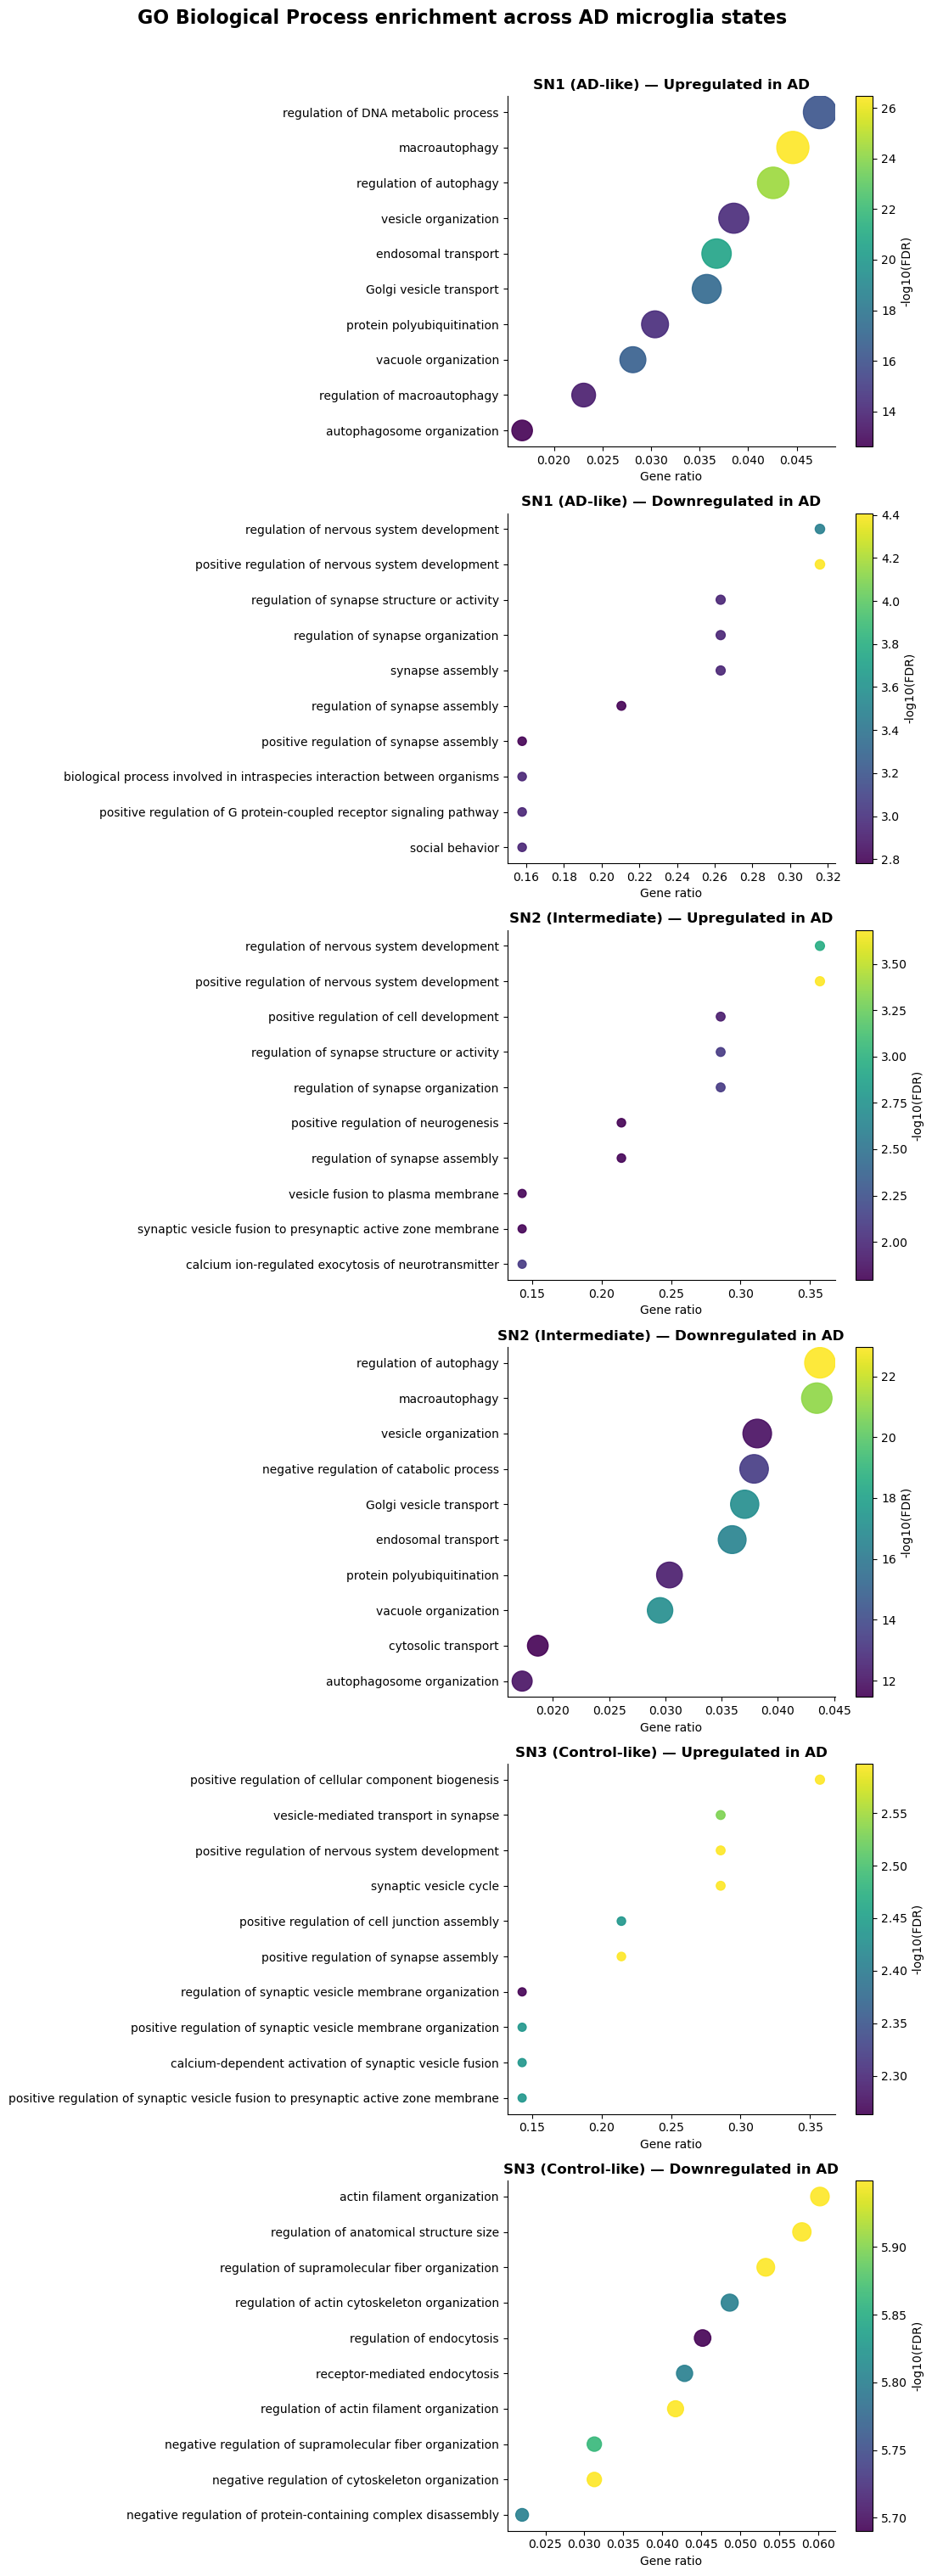

In [12]:
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DE_DIR = "AD_SN_DE"
ENRICH_DIR = "AD_SN_pathway_enrichment"
os.makedirs(ENRICH_DIR, exist_ok=True)

SN_LABELS = {"SN1": "AD-like", "SN2": "Intermediate", "SN3": "Control-like"}

# Check DE files
for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["upregulated", "downregulated"]:
        f = f"{DE_DIR}/{sn}_{direction}.csv"
        print(f, "FOUND" if os.path.exists(f) else "MISSING")



r_code = f'''
suppressPackageStartupMessages({{
    library(clusterProfiler)
    library(org.Hs.eg.db)
}})

DE_DIR <- "{DE_DIR}"
OUTDIR <- "{ENRICH_DIR}"

for (sn in c("SN1", "SN2", "SN3")) {{
    for (direction in c("Up", "Down")) {{

        suffix <- ifelse(direction == "Up", "upregulated", "downregulated")
        file <- file.path(DE_DIR, paste0(sn, "_", suffix, ".csv"))

        if (!file.exists(file)) {{
            cat("Missing:", file, "\\n")
            next
        }}

        dat <- read.csv(file, stringsAsFactors=FALSE)
        genes <- unique(na.omit(as.character(dat$gene)))
        genes <- genes[genes != ""]

        cat(sn, direction, ":", length(genes), "genes\\n")

        if (length(genes) < 3) {{
            cat("Too few genes — skipping\\n")
            next
        }}

        ego <- enrichGO(
            gene = genes,
            OrgDb = org.Hs.eg.db,
            keyType = "SYMBOL",
            ont = "BP",
            pAdjustMethod = "BH",
            pvalueCutoff = 0.05,
            qvalueCutoff = 0.20,
            readable = TRUE
        )

        res <- as.data.frame(ego)

        if (nrow(res) == 0) {{
            cat("No enrichment\\n")
            next
        }}

        res <- res[
            !is.na(res$p.adjust) &
            res$p.adjust < 0.05,
        ]

        if (nrow(res) == 0) {{
            cat("No FDR-significant pathways\\n")
            next
        }}

        ratio <- strsplit(as.character(res$GeneRatio), "/")

        res$GeneRatioNum <- sapply(
            ratio,
            function(x) as.numeric(x[1]) / as.numeric(x[2])
        )

        res$SN <- sn
        res$Direction <- direction

        outfile <- file.path(
            OUTDIR,
            paste0(sn, "_", direction, "_GO_BP.csv")
        )

        write.csv(res, outfile, row.names=FALSE)

        cat(
            "Saved:", outfile,
            "|", nrow(res), "pathways\\n"
        )
    }}
}}
'''

result = subprocess.run(
    ["Rscript", "-e", r_code],
    capture_output=True,
    text=True
)

print("\nR OUTPUT:")
print(result.stdout)

if result.stderr:
    print("\nR STDERR:")
    print(result.stderr)


plot_data = []

for sn in ["SN1", "SN2", "SN3"]:
    for direction in ["Up", "Down"]:

        f = f"{ENRICH_DIR}/{sn}_{direction}_GO_BP.csv"

        if os.path.exists(f):
            plot_data.append(
                (sn, direction, pd.read_csv(f))
            )

print("\nEnrichment plots available:", len(plot_data))

if plot_data:

    fig, axes = plt.subplots(
        len(plot_data),
        1,
        figsize=(11, 5 * len(plot_data))
    )

    axes = np.atleast_1d(axes)

    for ax, (sn, direction, df) in zip(axes, plot_data):

        top = (
            df.sort_values("p.adjust")
              .head(10)
              .sort_values("GeneRatioNum")
              .copy()
        )

        top["neglogFDR"] = -np.log10(
            top["p.adjust"].clip(lower=1e-300)
        )

        y = np.arange(len(top))

        scatter = ax.scatter(
            top["GeneRatioNum"],
            y,
            s=40 + top["Count"] * 4,
            c=top["neglogFDR"],
            cmap="viridis",
            alpha=0.9
        )

        ax.set_yticks(y)
        ax.set_yticklabels(top["Description"])

        ax.set_xlabel("Gene ratio")

        ax.set_title(
            f"{sn} ({SN_LABELS[sn]}) — {direction}regulated in AD",
            fontweight="bold"
        )

        plt.colorbar(
            scatter,
            ax=ax,
            label="-log10(FDR)"
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.suptitle(
        "GO Biological Process enrichment across AD microglia states",
        fontsize=16,
        fontweight="bold",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

else:
    print("No enrichment files were generated.")

# Visualization of super-neighborhood on UMAP (diffusion space)

In [16]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

ad_diff = sc.read_h5ad(
    "Microglia_AD_diffusion_CPP_scored.h5ad"
)

print("Loaded:", ad_diff)
print("Available obsm:", list(ad_diff.obsm.keys()))

sn_diff = pd.read_csv("microglia_SN_labels.csv")
sn_diff["cell"] = sn_diff["cell"].astype(str)

print("\nSaved SN labels:")
print(sn_diff["SN"].value_counts())

sn_map = sn_diff.set_index("cell")["SN"]

ad_diff.obs["SN"] = pd.Series(
    ad_diff.obs_names.astype(str),
    index=ad_diff.obs_names
).map(sn_map)

print("\nMapped SN counts:")
print(ad_diff.obs["SN"].value_counts(dropna=False))

print(
    "\nFraction assigned:",
    ad_diff.obs["SN"].notna().mean()
)


ad_plot = ad_diff[
    ad_diff.obs["SN"].notna()
].copy()

ad_plot.obs["SN"] = pd.Categorical(
    ad_plot.obs["SN"],
    categories=["SN1", "SN2", "SN3"],
    ordered=True
)

print("\nCells plotted:", ad_plot.n_obs)

Loaded: AnnData object with n_obs × n_vars = 72994 × 1
    obs: 'cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP'
    obsm: 'X_diffusion', 'X_pca'
Available obsm: ['X_diffusion', 'X_pca']

Saved SN labels:
SN
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64

Mapped SN counts:
SN
SN1    37938
SN2    24002
SN3     9265
NaN     1789
Name: count, dtype: int64

Fraction assigned: 0.9754911362577746

Cells plotted: 71205


In [8]:
print(list(ad_diff.obsm.keys()))

['X_diffusion', 'X_pca']


Cells plotted: 71205
CPP_state
AD-like         37938
Intermediate    24002
Control-like     9265
Name: count, dtype: int64


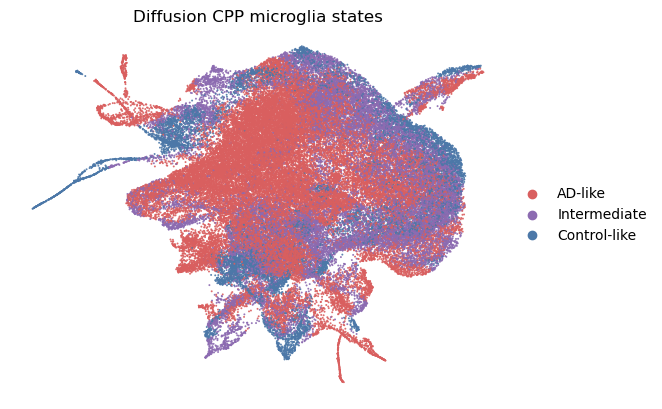

In [12]:
import scanpy as sc
import pandas as pd

ad_diff = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")

sn_labels = pd.read_csv("microglia_SN_labels.csv")
sn_labels["cell"] = sn_labels["cell"].astype(str)

sn_map = sn_labels.set_index("cell")["SN"]

ad_plot = ad_diff.copy()
ad_plot.obs["SN"] = pd.Series(ad_plot.obs_names.astype(str), index=ad_plot.obs_names).map(sn_map)

ad_plot = ad_plot[ad_plot.obs["SN"].notna()].copy()

ad_plot.obs["CPP_state"] = ad_plot.obs["SN"].map({
    "SN1": "AD-like",
    "SN2": "Intermediate",
    "SN3": "Control-like"
})

ad_plot.obs["CPP_state"] = pd.Categorical(
    ad_plot.obs["CPP_state"],
    categories=["AD-like", "Intermediate", "Control-like"],
    ordered=True
)

sc.pp.neighbors(
    ad_plot,
    use_rep="X_diffusion",
    n_neighbors=30,
    metric="euclidean",
    random_state=42
)

sc.tl.umap(
    ad_plot,
    random_state=42
)

ad_plot.uns["CPP_state_colors"] = ["#D95F5F", "#8C6BB1", "#4C78A8"]

print("Cells plotted:", ad_plot.n_obs)
print(ad_plot.obs["CPP_state"].value_counts())

sc.pl.umap(
    ad_plot,
    color="CPP_state",
    title="Diffusion CPP microglia states",
    size=8,
    alpha=0.9,
    legend_loc="right margin",
    frameon=False
)

In [96]:
print(adata_sn.obs.columns.tolist())

['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'super_neighborhood', 'SN_TRUE']


In [97]:
diffusion_labels = pd.DataFrame({
    "cell": adata_sn.obs_names.astype(str),
    "diffusion_SN": adata_sn.obs["super_neighborhood"].astype(str).values
})

diffusion_labels.to_csv("diffusion_SN_labels.csv", index=False)

print(diffusion_labels["diffusion_SN"].value_counts())

diffusion_SN
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64


In [55]:
import pandas as pd

# Save Diffusion CPP scores
diff_save = scores[["AD_score"]].copy()
diff_save = diff_save.rename(columns={"AD_score": "diffusion_cpp_score"})

# Cell IDs
diff_save.index = diff_save.index.astype(str)
diff_save.index.name = "cell"
diff_save = diff_save.reset_index()

# Save
diff_save.to_csv("diffusion_CPP_scores.csv", index=False)

# Check
print("Shape:", diff_save.shape)
print("Valid scores:", diff_save["diffusion_cpp_score"].notna().sum())
display(diff_save.head())

Shape: (72994, 2)
Valid scores: 71205


,cell,diffusion_cpp_score
0,AACTTTCAGGATGGTC-1-0,-0.279968
1,ACGGGCTCAATCAGAA-1-0,0.279611
2,AGCGGTCAGATGTTAG-1-0,-0.125046
3,AGTGAGGGTGGTAACG-1-0,-0.059390
4,ATTACTCAGGAGTAGA-1-0,-0.012446


In [56]:
import numpy as np
import pandas as pd

X_diff = np.asarray(adata.obsm["X_diffusion"])

diffusion_embedding = pd.DataFrame(
    X_diff,
    index=adata.obs_names.astype(str),
    columns=[f"diffusion_{i+1}" for i in range(X_diff.shape[1])]
)

diffusion_embedding.index.name = "cell"
diffusion_embedding = diffusion_embedding.reset_index()

diffusion_embedding.to_csv("diffusion_X_embedding.csv", index=False)

print("Saved shape:", diffusion_embedding.shape)
display(diffusion_embedding.head())

Saved shape: (72994, 13)


,cell,diffusion_1,diffusion_2,diffusion_3,diffusion_4,diffusion_5,diffusion_6,diffusion_7,diffusion_8,diffusion_9,diffusion_10,diffusion_11,diffusion_12
0,AACTTTCAGGATGGTC-1-0,-0.000986,0.002944,0.002052,-0.000924,0.002595,-0.001175,0.000193,0.001176,-0.001084,0.000125,0.000168,0.001065
1,ACGGGCTCAATCAGAA-1-0,-0.001080,0.001273,0.002109,-0.000551,-0.000614,-0.000105,-0.000028,0.000496,0.000071,-0.000416,-0.000260,0.000763
2,AGCGGTCAGATGTTAG-1-0,0.000755,0.002681,0.001180,-0.002321,0.002108,-0.000316,0.001140,0.001032,0.000220,-0.000587,-0.000660,-0.000289
3,AGTGAGGGTGGTAACG-1-0,-0.002592,0.002943,0.003085,-0.000081,0.002796,-0.001333,-0.000287,0.001502,0.000086,-0.000807,-0.001078,0.001503
4,ATTACTCAGGAGTAGA-1-0,-0.000776,0.002102,0.002293,-0.001603,0.000703,-0.000521,0.000405,0.000981,0.000199,-0.000547,-0.000627,0.000128


In [60]:
sn = pd.read_csv("diffusion_SN_labels.csv")
print(sn.columns.tolist())
print(sn.head())

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
['cell', 'diffusion_SN']
                   cell diffusion_SN
0  AACTTTCAGGATGGTC-1-0          SN2
1  ACGGGCTCAATCAGAA-1-0          SN1
2  AGCGGTCAGATGTTAG-1-0          SN2
3  AGTGAGGGTGGTAACG-1-0          SN2
4  ATTACTCAGGAGTAGA-1-0          SN2


In [61]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
ad = sc.read_h5ad("Microglia_full_counts.h5ad")

# Diffusion coordinates
diff = pd.read_csv("diffusion_X_embedding.csv").set_index("cell")
common = ad.obs_names.intersection(diff.index)
ad = ad[common].copy()
ad.obsm["X_diffusion"] = diff.loc[ad.obs_names].values

# Diffusion SN labels
sn = pd.read_csv("diffusion_SN_labels.csv").set_index("cell")
ad.obs["super_neighborhood"] = sn.reindex(ad.obs_names)["diffusion_SN"].values

# Diffusion CPP scores
scores = pd.read_csv("diffusion_CPP_scores.csv").set_index("cell")
ad.obs["AD_score"] = scores.reindex(ad.obs_names)["diffusion_cpp_score"].values

# Keep cells with complete Diffusion information
ad = ad[ad.obs["super_neighborhood"].notna() & ad.obs["AD_score"].notna()].copy()

print("Cells:", ad.n_obs)
print("Diffusion shape:", ad.obsm["X_diffusion"].shape)
print("\nSN counts:")
print(ad.obs["super_neighborhood"].value_counts())
print("\nCPP score:")
print(ad.obs["AD_score"].describe())

Cells: 71205
Diffusion shape: (71205, 12)

SN counts:
super_neighborhood
SN1    37938
SN2    24002
SN3     9265
Name: count, dtype: int64

CPP score:
count    71205.000000
mean         0.061515
std          0.470606
min         -1.416351
25%         -0.261077
50%          0.057095
75%          0.396787
max          1.579821
Name: AD_score, dtype: float64


                    count          mean    median       std
super_neighborhood                                         
SN1                 37938  1.000000e+00  0.901321  0.698432
SN2                 24002  5.635460e-01  0.459749  0.659120
SN3                  9265  6.889135e-16  0.260346  1.297944


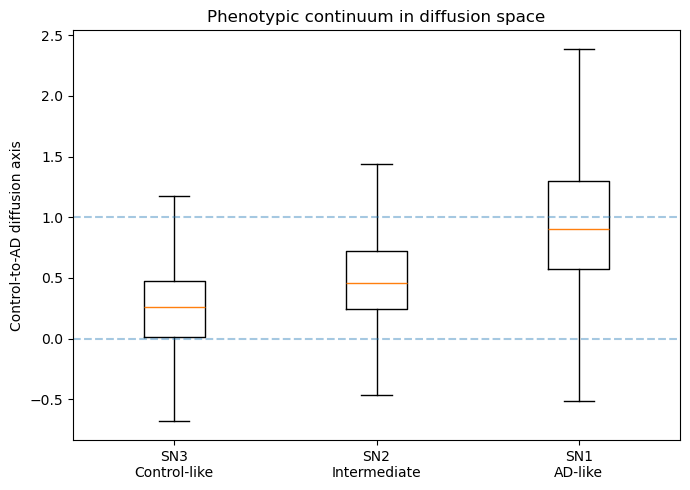

In [63]:
# ============================================================
# CONTROL-LIKE -> AD-LIKE DIFFUSION AXIS
# ============================================================

X = ad.obsm["X_diffusion"]
sn = ad.obs["super_neighborhood"].values

# Centroids of control-like and AD-like states
c_control = X[sn == "SN3"].mean(axis=0)
c_ad = X[sn == "SN1"].mean(axis=0)

# Axis from control-like -> AD-like
axis = c_ad - c_control
axis = axis / np.linalg.norm(axis)

# Project every cell onto axis
trajectory = (X - c_control) @ axis

# Scale to 0-1 using the two centroids
ad_centroid_position = (c_ad - c_control) @ axis
ad.obs["disease_axis"] = trajectory / ad_centroid_position

# Summary
summary = ad.obs.groupby("super_neighborhood")["disease_axis"].agg(["count","mean","median","std"])
print(summary)

# Plot
order = ["SN3","SN2","SN1"]
data = [ad.obs.loc[ad.obs["super_neighborhood"] == s, "disease_axis"].values for s in order]

plt.figure(figsize=(7,5))
plt.boxplot(data, tick_labels=["SN3\nControl-like","SN2\nIntermediate","SN1\nAD-like"], showfliers=False)
plt.axhline(0, linestyle="--", alpha=.4)
plt.axhline(1, linestyle="--", alpha=.4)
plt.ylabel("Control-to-AD diffusion axis")
plt.title("Phenotypic continuum in diffusion space")
plt.tight_layout()
plt.show()

In [67]:
# Recreate control-to-AD diffusion axis
X = ad.obsm["X_diffusion"]
sn = ad.obs["super_neighborhood"].values

c_control = X[sn == "SN3"].mean(axis=0)
c_ad = X[sn == "SN1"].mean(axis=0)

axis = c_ad - c_control
axis = axis / np.linalg.norm(axis)

trajectory = (X - c_control) @ axis
ad_centroid_position = (c_ad - c_control) @ axis

ad.obs["disease_axis"] = trajectory / ad_centroid_position

print(ad.obs["disease_axis"].describe())

count    71205.000000
mean         0.722761
std          0.861969
min         -8.091454
25%          0.328027
50%          0.635372
75%          1.061318
max          4.235185
Name: disease_axis, dtype: float64


    bin  axis_mean  AD_fraction  n_cells
0     0  -1.185018     0.375737     3561
1     1  -0.022763     0.417416     3560
2     2   0.116721     0.412079     3560
3     3   0.213892     0.448876     3560
4     4   0.292755     0.467565     3561
5     5   0.360082     0.482584     3560
6     6   0.421288     0.481742     3560
7     7   0.481999     0.507022     3560
8     8   0.542560     0.523876     3560
9     9   0.603321     0.573154     3561
10   10   0.670239     0.589607     3560
11   11   0.744035     0.585955     3560
12   12   0.826185     0.599157     3560
13   13   0.914946     0.608146     3560
14   14   1.010190     0.627071     3561
15   15   1.117603     0.660112     3560
16   16   1.251408     0.684831     3560
17   17   1.453294     0.694663     3560
18   18   1.844457     0.711798     3560
19   19   2.798064     0.630160     3561


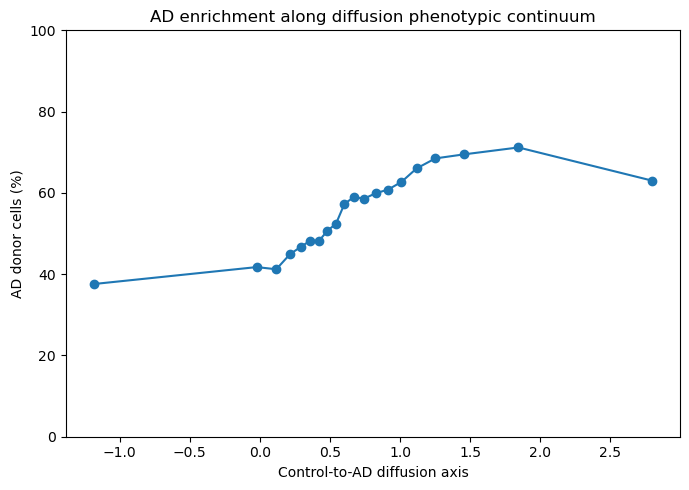

In [69]:
# ============================================================
# AD ENRICHMENT ALONG CONTROL -> AD DIFFUSION AXIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create disease axis
X = ad.obsm["X_diffusion"]
sn = ad.obs["super_neighborhood"].astype(str).values

c_control = X[sn == "SN3"].mean(axis=0)
c_ad = X[sn == "SN1"].mean(axis=0)

axis = c_ad - c_control
axis = axis / np.linalg.norm(axis)

trajectory = (X - c_control) @ axis
scale = (c_ad - c_control) @ axis

ad.obs["disease_axis"] = trajectory / scale

# Diagnosis
df = ad.obs[["disease_axis", "Pathologic_diagnosis_of_AD"]].dropna().copy()
df["AD"] = df["Pathologic_diagnosis_of_AD"].astype(str).str.lower().eq("yes").astype(int)

# Divide cells into 20 equal-sized bins along disease axis
df["bin"] = pd.qcut(df["disease_axis"], 20, labels=False, duplicates="drop")

# AD fraction in each bin
trend = df.groupby("bin", observed=True).agg(axis_mean=("disease_axis","mean"), AD_fraction=("AD","mean"), n_cells=("AD","size")).reset_index()

print(trend)

# Plot
plt.figure(figsize=(7,5))
plt.plot(trend["axis_mean"], trend["AD_fraction"] * 100, marker="o")
plt.xlabel("Control-to-AD diffusion axis")
plt.ylabel("AD donor cells (%)")
plt.title("AD enrichment along diffusion phenotypic continuum")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

/var/folders/p6/cq9gp3h96hlb1x705pvg849m0000gn/T/ipykernel_39282/1240485429.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  check = donor.groupby("subject")["diagnosis"].nunique()


Donors: 424
AD donors: 235
Control donors: 189
Mean median-axis | AD: 0.7331252077455308
Mean median-axis | Control: 0.4913650599849259
Observed AD - Control: 0.2417601477606049
Permutation p-value: 9.999000099990002e-05
Cohen's d: 0.48482782183782447


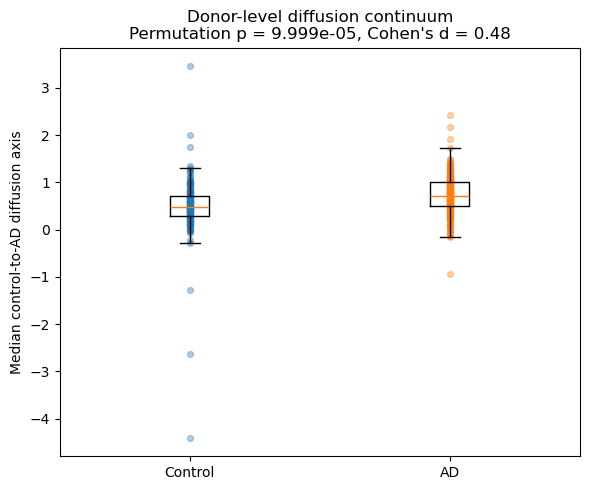

In [70]:
# ============================================================
# DONOR-LEVEL VALIDATION OF DIFFUSION DISEASE AXIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Build donor-level table
donor = ad.obs[["subject", "Pathologic_diagnosis_of_AD", "disease_axis"]].dropna().copy()
donor["diagnosis"] = donor["Pathologic_diagnosis_of_AD"].astype(str).str.lower()
donor = donor[donor["diagnosis"].isin(["yes","no"])]

donor_summary = donor.groupby("subject", observed=True).agg(
    diagnosis=("diagnosis","first"),
    axis_median=("disease_axis","median"),
    axis_mean=("disease_axis","mean"),
    n_cells=("disease_axis","size")
).reset_index()

# Check diagnosis is consistent within each donor
check = donor.groupby("subject")["diagnosis"].nunique()
assert check.max() == 1

# Observed AD - Control difference
ad_vals = donor_summary.loc[donor_summary["diagnosis"] == "yes", "axis_median"].values
cn_vals = donor_summary.loc[donor_summary["diagnosis"] == "no", "axis_median"].values
observed = ad_vals.mean() - cn_vals.mean()

print("Donors:", len(donor_summary))
print("AD donors:", len(ad_vals))
print("Control donors:", len(cn_vals))
print("Mean median-axis | AD:", ad_vals.mean())
print("Mean median-axis | Control:", cn_vals.mean())
print("Observed AD - Control:", observed)

# ============================================================
# DONOR-LEVEL PERMUTATION TEST
# ============================================================

rng = np.random.default_rng(42)
N_PERM = 10000

values = donor_summary["axis_median"].values
labels = donor_summary["diagnosis"].values

null = np.empty(N_PERM)

for i in range(N_PERM):
    perm = rng.permutation(labels)
    null[i] = values[perm == "yes"].mean() - values[perm == "no"].mean()

p_perm = (np.sum(np.abs(null) >= abs(observed)) + 1) / (N_PERM + 1)

print("Permutation p-value:", p_perm)

# Effect size
pooled_sd = np.sqrt(((len(ad_vals)-1)*ad_vals.var(ddof=1) + (len(cn_vals)-1)*cn_vals.var(ddof=1)) / (len(ad_vals)+len(cn_vals)-2))
cohens_d = observed / pooled_sd

print("Cohen's d:", cohens_d)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(6,5))
plt.boxplot([cn_vals, ad_vals], tick_labels=["Control","AD"], showfliers=False)
plt.scatter(np.ones(len(cn_vals)), cn_vals, alpha=.35, s=18)
plt.scatter(np.ones(len(ad_vals))*2, ad_vals, alpha=.35, s=18)
plt.ylabel("Median control-to-AD diffusion axis")
plt.title(f"Donor-level diffusion continuum\nPermutation p = {p_perm:.4g}, Cohen's d = {cohens_d:.2f}")
plt.tight_layout()
plt.show()

# Amyloid trajectory analysis

In [17]:
import pandas as pd
import numpy as np

meta = pd.read_csv("Metadata.csv")

print("Metadata shape:", meta.shape)
print(meta[["projid", "study", "amyloid", "plaq_d", "plaq_n"]].head(10))

Metadata shape: (427, 127)
    projid study    amyloid    plaq_d    plaq_n
0  1211411  ROS    0.000000  0.076346  0.000000
1  2899847  MAP    0.266250  0.020682  0.131488
2  3713990  MAP    6.201875  0.758098  0.643317
3  3889845  MAP    6.644375  0.303321  0.995753
4  6107196  MAP    5.075625  0.846022  1.137356
5  6804844  MAP   10.342500  0.904957  1.029172
6  7253015  MAP   18.348125  1.004650  1.067751
7  7265221  MAP    8.587083  1.034088  1.259668
8  7311370  MAP    9.972812  0.876964  1.057094
9  8109170  MAP    3.147500  0.693926  0.436478


In [18]:
import scanpy as sc
import pandas as pd

ad_diff = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")

print("Metadata donors:", meta["projid"].nunique())
print("Microglia donors:", ad_diff.obs["subject"].nunique())

print("\nMetadata IDs:")
print(meta["projid"].head(10).tolist())

print("\nMicroglia IDs:")
print(ad_diff.obs["subject"].unique()[:10])

Metadata donors: 427
Microglia donors: 424

Metadata IDs:
[1211411, 2899847, 3713990, 3889845, 6107196, 6804844, 7253015, 7265221, 7311370, 8109170]

Microglia IDs:
['ROSMAP-52226', 'ROSMAP-72912', 'ROSMAP-66835', 'ROSMAP-90257', 'ROSMAP-38740', 'ROSMAP-70347', 'ROSMAP-54289', 'ROSMAP-61943', 'ROSMAP-25704', 'ROSMAP-93570']
Categories (424, object): ['ROSMAP-10132', 'ROSMAP-10643', 'ROSMAP-10859', 'ROSMAP-12078', ..., 'ROSMAP-98683', 'ROSMAP-99419', 'ROSMAP-99585', 'ROSMAP-99981']


In [19]:
meta_ids = set(meta["projid"].astype(str))

microglia_ids = set(
    ad_diff.obs["subject"]
    .astype(str)
    .str.replace("ROSMAP-", "", regex=False)
)

matches = meta_ids.intersection(microglia_ids)

print("Matching donors:", len(matches))
print("Microglia donors without matches:", len(microglia_ids - meta_ids))
print("Example matches:", list(matches)[:10])

Matching donors: 0
Microglia donors without matches: 424
Example matches: []


In [20]:
files = ["individual_metadata_deidentified.tsv", "microglia_metadata.csv"]

for file in files:
    df = pd.read_csv(file, sep="\t" if file.endswith(".tsv") else ",")
    print("\nFILE:", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string())


FILE: individual_metadata_deidentified.tsv
Shape: (427, 6)
Columns: ['subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']
        subject  msex age_death   pmi  race Pathologic_diagnosis_of_AD
0  ROSMAP-10132     0       90+   7.0     1                        yes
1  ROSMAP-10643     0       90+  13.0     1                        yes
2  ROSMAP-10859     1   (80,85]  14.0     2                        yes

FILE: microglia_metadata.csv
Shape: (72994, 8)
Columns: ['Unnamed: 0', 'cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']
             Unnamed: 0 cell_type_high_resolution       subject  msex age_death  pmi  race Pathologic_diagnosis_of_AD
0  AACTTTCAGGATGGTC-1-0                Mic P2RY12  ROSMAP-52226     1   (80,85]    1     1                         no
1  ACGGGCTCAATCAGAA-1-0                Mic P2RY12  ROSMAP-52226     1   (80,85]    1     1                         no
2  AGCGGTCAGATGTTAG-1-0              

In [21]:
donor = pd.read_csv("individual_metadata_deidentified.tsv", sep="\t")

print("Same number of rows:", len(meta) == len(donor))
print("Unique projids:", meta["projid"].nunique())
print("Unique subjects:", donor["subject"].nunique())

print("\nFirst 10 rows:")
print(pd.DataFrame({
    "projid": meta["projid"].head(10),
    "subject": donor["subject"].head(10),
    "PMI_metadata": meta["pmi"].head(10),
    "PMI_donor": donor["pmi"].head(10)
}))

print("\nPMI exact matches by row:",
      np.isclose(pd.to_numeric(meta["pmi"], errors="coerce"),
                 pd.to_numeric(donor["pmi"], errors="coerce"),
                 equal_nan=True).sum())

Same number of rows: True
Unique projids: 427
Unique subjects: 427

First 10 rows:
    projid       subject  PMI_metadata  PMI_donor
0  1211411  ROSMAP-10132      6.500000        7.0
1  2899847  ROSMAP-10643      7.016667       13.0
2  3713990  ROSMAP-10859      4.333333       14.0
3  3889845  ROSMAP-12078      6.916667        3.0
4  6107196  ROSMAP-12256      4.166667        4.0
5  6804844  ROSMAP-12311      8.416667        5.0
6  7253015  ROSMAP-12562      4.166667       21.0
7  7265221  ROSMAP-12795      5.750000        7.0
8  7311370  ROSMAP-12832      7.583333        7.0
9  8109170  ROSMAP-13327      5.450000        5.0

PMI exact matches by row: 4


In [22]:
print(ad_diff.obs.columns.tolist())

['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP']


# Intermediate state analysis

In [23]:
print(ad_diff.obs.columns.tolist())

['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP']


In [5]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

ad_diff = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")
sn_labels = pd.read_csv("microglia_SN_labels.csv")

print("Diffusion dataset:", ad_diff.shape)
print("SN labels:", sn_labels.shape)
print("Label columns:", sn_labels.columns.tolist())
print(sn_labels.head())

Diffusion dataset: (72994, 1)
SN labels: (71205, 2)
Label columns: ['cell', 'SN']
                   cell   SN
0  AACTTTCAGGATGGTC-1-0  SN2
1  ACGGGCTCAATCAGAA-1-0  SN1
2  AGCGGTCAGATGTTAG-1-0  SN2
3  AGTGAGGGTGGTAACG-1-0  SN2
4  ATTACTCAGGAGTAGA-1-0  SN2


In [6]:
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
from scipy.sparse.csgraph import connected_components

ad_graph = ad_diff.copy()

sc.pp.neighbors(ad_graph, use_rep="X_diffusion", n_neighbors=30, metric="euclidean", random_state=42)

W = ad_graph.obsp["connectivities"].copy()
W.setdiag(0)
W.eliminate_zeros()

G = nx.from_scipy_sparse_array(W, edge_attribute="weight")

print("Cells:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))

Cells: 72994
Edges: 1471916
Connected components: 1


In [7]:
import pandas as pd

sn = pd.read_csv("microglia_SN_labels.csv")

print(sn.shape)
print(sn.columns.tolist())
display(sn.head())

(71205, 2)
['cell', 'SN']


,cell,SN
0,AACTTTCAGGATGGTC-1-0,SN2
1,ACGGGCTCAATCAGAA-1-0,SN1
2,AGCGGTCAGATGTTAG-1-0,SN2
3,AGTGAGGGTGGTAACG-1-0,SN2
4,ATTACTCAGGAGTAGA-1-0,SN2


In [8]:
print("Graph cell examples:", ad_graph.obs_names[:5].tolist())
print("CSV examples:")
display(sn.head())

Graph cell examples: ['AACTTTCAGGATGGTC-1-0', 'ACGGGCTCAATCAGAA-1-0', 'AGCGGTCAGATGTTAG-1-0', 'AGTGAGGGTGGTAACG-1-0', 'ATTACTCAGGAGTAGA-1-0']
CSV examples:


,cell,SN
0,AACTTTCAGGATGGTC-1-0,SN2
1,ACGGGCTCAATCAGAA-1-0,SN1
2,AGCGGTCAGATGTTAG-1-0,SN2
3,AGTGAGGGTGGTAACG-1-0,SN2
4,ATTACTCAGGAGTAGA-1-0,SN2


In [9]:
sn = pd.read_csv("microglia_SN_labels.csv", index_col=0)

print(sn.columns.tolist())
print("Matching cells:", ad_graph.obs_names.isin(sn.index).sum())

['SN']
Matching cells: 71205


In [10]:
ad_graph.obs["SN"] = sn["SN"].reindex(ad_graph.obs_names)

print(ad_graph.obs["SN"].value_counts(dropna=False))

SN
SN1    37938
SN2    24002
SN3     9265
NaN     1789
Name: count, dtype: int64


In [11]:
import numpy as np

W = ad_graph.obsp["connectivities"].copy().tocsr()
W.setdiag(0)
W.eliminate_zeros()

labels = ad_graph.obs["SN"].astype("string").to_numpy()

coo = W.tocoo()

edges = pd.DataFrame({
    "source": labels[coo.row],
    "target": labels[coo.col],
    "weight": coo.data
}).dropna()

connectivity = edges.groupby(["source", "target"])["weight"].sum().unstack(fill_value=0)
connectivity = connectivity.div(connectivity.sum(axis=1), axis=0)

display(connectivity.round(3))

target,SN1,SN2,SN3
source,,,
SN1,0.894,0.102,0.004
SN2,0.160,0.762,0.078
SN3,0.016,0.200,0.784


In [12]:

import numpy as np
import pandas as pd
from scipy.sparse.csgraph import dijkstra

rng = np.random.default_rng(42)

valid = ad_graph.obs["SN"].isin(["SN1", "SN2", "SN3"]).to_numpy()
labels = ad_graph.obs["SN"].to_numpy()[valid]
W_valid = W[valid][:, valid].tocsr()

W_valid = W_valid.maximum(W_valid.T).tocsr()
W_valid.setdiag(0)
W_valid.eliminate_zeros()

D = W_valid.copy()
D.data = 1 / np.maximum(D.data, 1e-8)

sn3 = np.flatnonzero(labels == "SN3")
sn1 = np.flatnonzero(labels == "SN1")

n_ref = min(30, len(sn3), len(sn1))

ref_sn3 = rng.choice(sn3, n_ref, replace=False)
ref_sn1 = rng.choice(sn1, n_ref, replace=False)

dist_sn3 = dijkstra(D, directed=False, indices=ref_sn3).min(axis=0)
dist_sn1 = dijkstra(D, directed=False, indices=ref_sn1).min(axis=0)

position = dist_sn3 / (dist_sn3 + dist_sn1)

graph_df = pd.DataFrame({
    "SN": labels,
    "position": position,
    "distance_SN3": dist_sn3,
    "distance_SN1": dist_sn1
})

graph_df = graph_df.replace([np.inf, -np.inf], np.nan).dropna()

display(graph_df.groupby("SN")[["position", "distance_SN3", "distance_SN1"]].median().round(4))


,position,distance_SN3,distance_SN1
SN,,,
SN1,0.5900,14.3446,9.9621
SN2,0.4965,11.8369,12.3121
SN3,0.3950,8.7538,13.7304


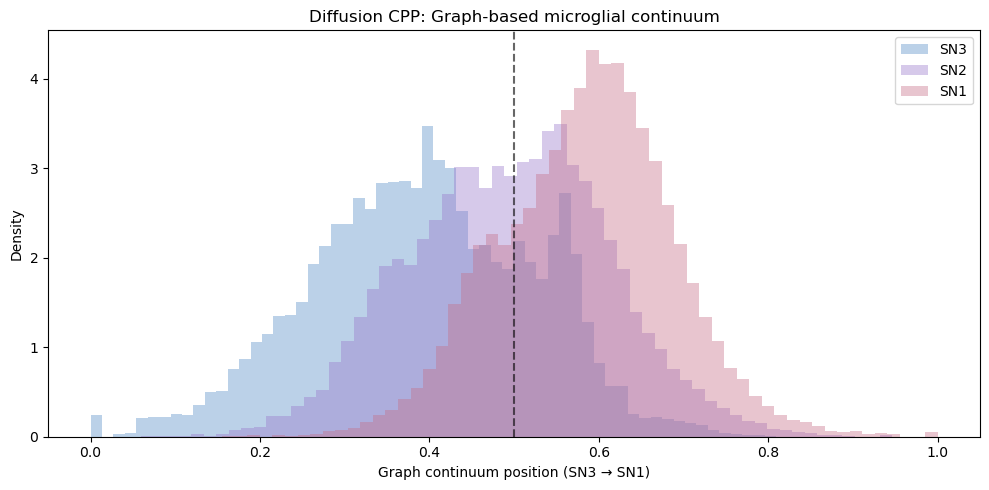

Median graph position:
SN
SN1    0.5900
SN2    0.4965
SN3    0.3950
Name: position, dtype: float64


In [13]:

import matplotlib.pyplot as plt

colors = {"SN1": "#C66F89", "SN2": "#9A78CC", "SN3": "#568CC6"}

plt.figure(figsize=(10, 5))

for state in ["SN3", "SN2", "SN1"]:
    values = graph_df.loc[graph_df["SN"] == state, "position"]
    plt.hist(values, bins=60, density=True, alpha=0.4, color=colors[state], label=state)

plt.axvline(0.5, color="black", linestyle="--", alpha=0.6)
plt.xlabel("Graph continuum position (SN3 → SN1)")
plt.ylabel("Density")
plt.title("Diffusion CPP: Graph-based microglial continuum")
plt.legend()
plt.tight_layout()
plt.show()

print("Median graph position:")
print(graph_df.groupby("SN")["position"].median().round(4))


In [14]:

from scipy.stats import kruskal, mannwhitneyu

x3 = graph_df.loc[graph_df["SN"] == "SN3", "position"].to_numpy()
x2 = graph_df.loc[graph_df["SN"] == "SN2", "position"].to_numpy()
x1 = graph_df.loc[graph_df["SN"] == "SN1", "position"].to_numpy()

medians = graph_df.groupby("SN")["position"].median()
ordered = medians["SN3"] < medians["SN2"] < medians["SN1"]

H, p_global = kruskal(x3, x2, x1)
p_32 = mannwhitneyu(x3, x2, alternative="less").pvalue
p_21 = mannwhitneyu(x2, x1, alternative="less").pvalue

print("SN3 < SN2 < SN1:", ordered)
print(f"Kruskal-Wallis p: {p_global:.6g}")
print(f"SN3 < SN2 p: {p_32:.6g}")
print(f"SN2 < SN1 p: {p_21:.6g}")


SN3 < SN2 < SN1: True
Kruskal-Wallis p: 0
SN3 < SN2 p: 0
SN2 < SN1 p: 0


Fraction of repeats with SN3 < SN2 < SN1: 1.0


,SN3,SN2,SN1
count,20.0000,20.0000,20.0000
mean,0.3811,0.4910,0.5859
std,0.0148,0.0154,0.0120
min,0.3543,0.4697,0.5626
25%,0.3697,0.4796,0.5796
50%,0.3809,0.4895,0.5851
75%,0.3943,0.4983,0.5927
max,0.4025,0.5259,0.6128


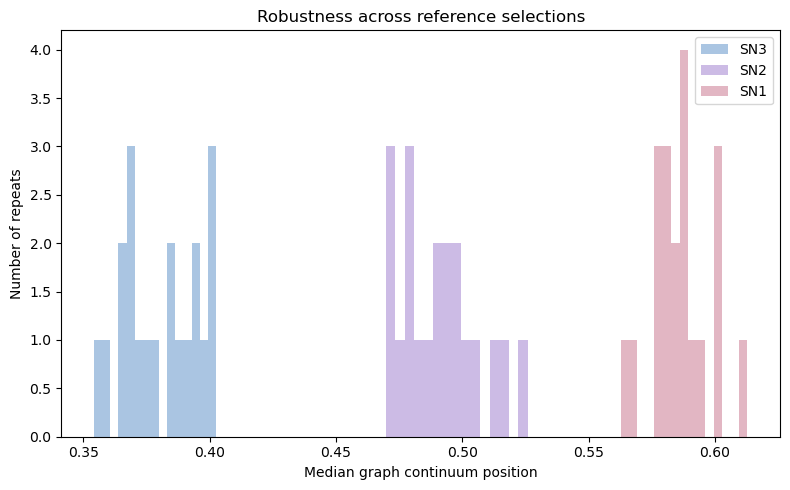

In [15]:

rng = np.random.default_rng(123)

records = []

for repeat in range(20):
    ref3 = rng.choice(sn3, n_ref, replace=False)
    ref1 = rng.choice(sn1, n_ref, replace=False)

    d3 = dijkstra(D, directed=False, indices=ref3).min(axis=0)
    d1 = dijkstra(D, directed=False, indices=ref1).min(axis=0)

    pos = d3 / (d3 + d1)

    temp = pd.DataFrame({"SN": labels, "position": pos})
    temp = temp.replace([np.inf, -np.inf], np.nan).dropna()

    m = temp.groupby("SN")["position"].median()

    records.append({
        "repeat": repeat,
        "SN3": m["SN3"],
        "SN2": m["SN2"],
        "SN1": m["SN1"],
        "ordered": m["SN3"] < m["SN2"] < m["SN1"]
    })

robustness = pd.DataFrame(records)

print("Fraction of repeats with SN3 < SN2 < SN1:", robustness["ordered"].mean())
display(robustness[["SN3", "SN2", "SN1"]].describe().round(4))

plt.figure(figsize=(8, 5))

for state in ["SN3", "SN2", "SN1"]:
    plt.hist(robustness[state], bins=15, alpha=0.5, color=colors[state], label=state)

plt.xlabel("Median graph continuum position")
plt.ylabel("Number of repeats")
plt.title("Robustness across reference selections")
plt.legend()
plt.tight_layout()
plt.show()


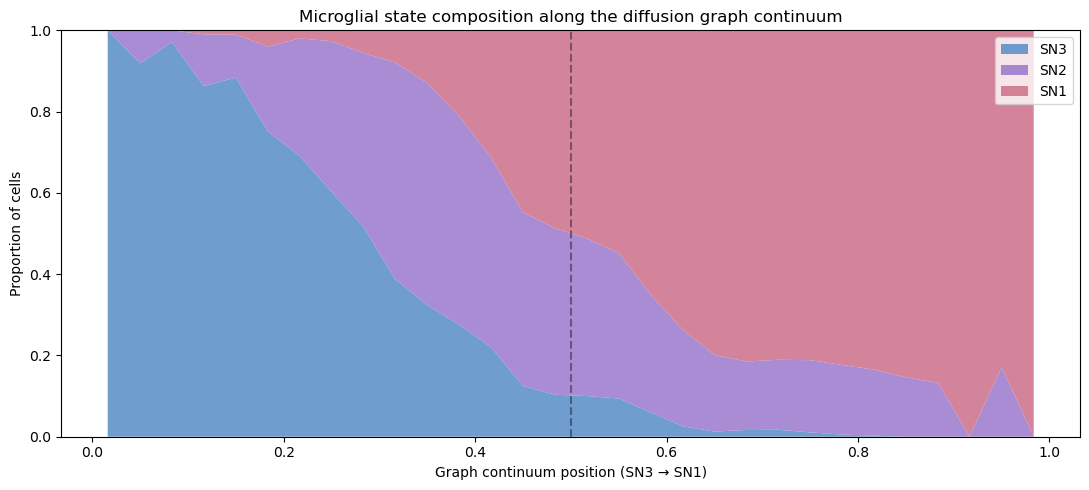

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = graph_df[["SN", "position"]].dropna().copy()
df = df[df["SN"].isin(["SN1", "SN2", "SN3"])]

bins = np.linspace(0, 1, 31)
df["bin"] = pd.cut(df["position"], bins=bins, include_lowest=True)

counts = pd.crosstab(df["bin"], df["SN"]).reindex(columns=["SN3", "SN2", "SN1"], fill_value=0)
fractions = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)

centers = np.array([interval.mid for interval in counts.index])
mask = counts.sum(axis=1).to_numpy() >= 30

colors = ["#568CC6", "#9A78CC", "#CC6F89"]

plt.figure(figsize=(11, 5))
plt.stackplot(centers[mask], fractions.loc[mask].fillna(0).to_numpy().T,
              labels=["SN3", "SN2", "SN1"], colors=colors, alpha=0.85)

plt.axvline(0.5, color="black", linestyle="--", alpha=0.4)
plt.xlabel("Graph continuum position (SN3 → SN1)")
plt.ylabel("Proportion of cells")
plt.title("Microglial state composition along the diffusion graph continuum")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import scanpy as sc

ad_traj = ad_diff.copy()

sn = pd.read_csv("microglia_SN_labels.csv")
print(sn.head())
print(sn.columns.tolist())
print("Trajectory cells:", ad_traj.n_obs)

                   cell   SN
0  AACTTTCAGGATGGTC-1-0  SN2
1  ACGGGCTCAATCAGAA-1-0  SN1
2  AGCGGTCAGATGTTAG-1-0  SN2
3  AGTGAGGGTGGTAACG-1-0  SN2
4  ATTACTCAGGAGTAGA-1-0  SN2
['cell', 'SN']
Trajectory cells: 72994
